# Project Polaris
## Section 1 — Data Acquisition & Dataset Profiling

This section imports the operational datasets of the Indian polar research stations and performs initial quality assessment.

### Objectives
- Load Bharati, Maitri and Himadri datasets
- Inspect dataset dimensions
- Verify schema consistency
- Identify missing values and duplicate timestamps
- Generate a quality report before preprocessing

In [10]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [11]:
# ==========================================
# POLARIS : SECTION 1
# Import Required Libraries
# ==========================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

plt.style.use("ggplot")
pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


## 1.1 Load Operational Datasets

Three operational datasets are used:

| Station | Region |
|----------|---------|
| Bharati | East Antarctica |
| Maitri | Continental Antarctica |
| Himadri | Arctic (Svalbard) |

Each dataset follows the same operational structure and will be processed using a common pipeline.

In [12]:

# ==========================================
# Load datasets
# ==========================================

DATA_PATH = Path(".")

bharati_df = pd.read_csv(DATA_PATH / "bharati_simulated.csv")
maitri_df  = pd.read_csv(DATA_PATH / "maitri_simulated.csv")
himadri_df = pd.read_csv(DATA_PATH / "himadri_simulated.csv")

stations = {
    "Bharati": bharati_df,
    "Maitri": maitri_df,
    "Himadri": himadri_df
}

print("Datasets loaded successfully.")

Datasets loaded successfully.


## 1.2 Dataset Dimensions

The first validation step is to understand the size of each dataset before any preprocessing is performed.

In [13]:
summary = []

for name, df in stations.items():
    summary.append({
        "Station": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1]
    })

shape_df = pd.DataFrame(summary)
shape_df

,Station,Rows,Columns
0,Bharati,55520,30
1,Maitri,20631,26
2,Himadri,6584,27


## 1.3 Schema Consistency Check

Before building a common preprocessing pipeline, all datasets must contain identical column names and compatible data types.

In [14]:
# Reference schema (Maitri)
reference_columns = set(maitri_df.columns)

for name, df in stations.items():
    print(f"\n{name}")
    print("-"*30)

    missing = reference_columns - set(df.columns)
    extra = set(df.columns) - reference_columns

    print("Missing :", missing if missing else "None")
    print("Extra   :", extra if extra else "None")


Bharati
------------------------------
Missing : {'source'}
Extra   : {'wind_dir_deg_imputed', 'power_t2m_c', 'power_ws10m_ms', 'rh_pct_imputed', 'pressure_hpa_imputed'}

Maitri
------------------------------
Missing : None
Extra   : None

Himadri
------------------------------
Missing : {'ghi_kwh_m2_day', 'ghi_est_w_m2', 'source', 'ghi_clearsky_kwh_m2_day'}
Extra   : {'ghi_wh_m2', 'wind_dir_deg_imputed', 'ghi_clearsky_wh_m2', 'rh_pct_imputed', 'pressure_hpa_imputed'}


## 1.4 Data Quality Assessment

A research-grade dataset must be evaluated for:

- Missing values
- Duplicate records
- Duplicate timestamps
- Timestamp validity

This report determines whether preprocessing is required before analysis.

In [15]:
# ======================================================
# Common Operational Schema
# ======================================================

COMMON_COLUMNS = [
    "timestamp",
    "temp_c",
    "wind_speed_ms",
    "rh_pct",
    "pressure_hpa",
    "pv_output_kw",
    "wind_output_kw",
    "total_load_kw",
    "diesel_required_kw",
    "diesel_liters"
]

quality = []

for name, df in stations.items():

    temp = df.copy()
    temp["timestamp"] = pd.to_datetime(temp["timestamp"], errors="coerce")

    cols = [c for c in COMMON_COLUMNS if c in temp.columns]

    quality.append({
        "Station": name,
        "Rows": len(temp),
        "Columns": len(temp.columns),
        "Common Missing": int(temp[cols].isna().sum().sum()),
        "Duplicate Rows": int(temp.duplicated().sum()),
        "Duplicate Timestamps": int(temp["timestamp"].duplicated().sum()),
        "Invalid Timestamps": int(temp["timestamp"].isna().sum())
    })

quality_df = pd.DataFrame(quality)
quality_df

,Station,Rows,Columns,Common Missing,Duplicate Rows,Duplicate Timestamps,Invalid Timestamps
0,Bharati,55520,30,274,0,0,0
1,Maitri,20631,26,17886,0,0,0
2,Himadri,6584,27,0,0,0,0


In [16]:
# ======================================================
# Temporal Coverage of Each Station
# ======================================================

schema_summary = []

for name, df in stations.items():

    temp = df.copy()
    temp["timestamp"] = pd.to_datetime(temp["timestamp"])

    schema_summary.append({
        "Station": name,
        "Start Date": temp["timestamp"].min(),
        "End Date": temp["timestamp"].max(),
        "Records": len(temp)
    })

pd.DataFrame(schema_summary)

,Station,Start Date,End Date,Records
0,Bharati,2002-01-01 00:00:00,2020-12-31 21:00:00,55520
1,Maitri,2008-01-01 00:00:00,2015-12-31 21:00:00,20631
2,Himadri,2025-12-14 01:00:00,2026-09-14 08:00:00,6584


In [17]:
all_columns = sorted(set().union(*[set(df.columns) for df in stations.values()]))

schema = pd.DataFrame({
    "Column": all_columns,
    "Bharati": [c in bharati_df.columns for c in all_columns],
    "Maitri":  [c in maitri_df.columns for c in all_columns],
    "Himadri": [c in himadri_df.columns for c in all_columns]
})

schema

,Column,Bharati,Maitri,Himadri
0,cloud_factor,True,True,True
1,diesel_liters,True,True,True
2,diesel_required_kw,True,True,True
3,ghi_clearsky_kwh_m2_day,True,True,False
4,ghi_clearsky_wh_m2,False,False,True
5,ghi_est_w_m2,True,True,False
6,ghi_kwh_m2_day,True,True,False
7,ghi_wh_m2,False,False,True
8,heating_load_kw,True,True,True
9,net_load_kw,True,True,True


## 1.5 Data Types

The operational datasets contain numerical meteorological variables together with timestamp information.

The timestamp is converted into `datetime` format for future feature engineering.

In [18]:
for df in stations.values():
    df["timestamp"] = pd.to_datetime(df["timestamp"])

bharati_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55520 entries, 0 to 55519
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   timestamp                55520 non-null  datetime64[ns]
 1   temp_c                   55520 non-null  float64       
 2   pressure_hpa             55520 non-null  float64       
 3   wind_speed_ms            55482 non-null  float64       
 4   wind_dir_deg             55482 non-null  float64       
 5   rh_pct                   55284 non-null  float64       
 6   temp_c_imputed           55520 non-null  bool          
 7   pressure_hpa_imputed     55520 non-null  bool          
 8   wind_speed_ms_imputed    55520 non-null  bool          
 9   rh_pct_imputed           55520 non-null  bool          
 10  wind_dir_deg_imputed     55520 non-null  bool          
 11  ghi_kwh_m2_day           55520 non-null  float64       
 12  ghi_clearsky_kwh_m2_day  55520 n

## 1.6 Initial Dataset Preview

A preview is generated to verify that the imported data contains weather, renewable generation, electrical load and diesel variables.

In [19]:
bharati_df.head()

,timestamp,temp_c,pressure_hpa,wind_speed_ms,wind_dir_deg,rh_pct,temp_c_imputed,pressure_hpa_imputed,wind_speed_ms_imputed,rh_pct_imputed,wind_dir_deg_imputed,ghi_kwh_m2_day,ghi_clearsky_kwh_m2_day,power_t2m_c,power_ws10m_ms,cloud_factor,ghi_est_w_m2,occupancy,pv_output_kw_raw,pv_data_missing,pv_output_kw,wind_output_kw,renewable_output_kw,heating_load_kw,occupancy_load_kw,total_load_kw,net_load_kw,diesel_required_kw,surplus_renewable_kw,diesel_liters
0,2002-01-01 00:00:00,3.7,977.00,8.0,67.50,NaN,False,False,False,True,False,9.5054,10.2106,-1.1,12.31,0.930935,312.407178,45.682533,10.621844,False,10.621844,4.451455,15.073299,20.02,59.387294,114.407294,99.333994,99.333994,0.0,89.400595
1,2002-01-01 03:00:00,3.1,978.05,10.0,56.25,NaN,True,True,True,True,True,9.5054,10.2106,-1.1,12.31,0.930935,577.489260,45.682533,19.634635,False,19.634635,13.415428,33.050063,20.86,59.387294,115.247294,82.197230,82.197230,0.0,73.977507
2,2002-01-01 06:00:00,2.5,979.10,12.0,45.00,NaN,False,False,False,True,False,9.5054,10.2106,-1.1,12.31,0.930935,736.291566,45.682533,25.033913,False,25.033913,30.000000,55.033913,21.70,59.387294,116.087294,61.053380,61.053380,0.0,54.948042
3,2002-01-01 09:00:00,2.2,980.00,10.5,56.25,NaN,True,True,True,True,True,9.5054,10.2106,-1.1,12.31,0.930935,695.789858,45.682533,23.656855,False,23.656855,16.755547,40.412402,22.12,59.387294,116.507294,76.094892,76.094892,0.0,68.485403
4,2002-01-01 12:00:00,1.9,980.90,9.0,67.50,NaN,False,False,False,True,False,9.5054,10.2106,-1.1,12.31,0.930935,479.709489,45.682533,16.310123,False,16.310123,8.127417,24.437540,22.54,59.387294,116.927294,92.489754,92.489754,0.0,83.240778


# Section 2 — Schema Standardization & Data Preprocessing

The three datasets originate from different meteorological sources (IMD, NASA POWER and simulated operational data). Although they represent similar variables, several columns use different names and units.

This section creates a **canonical operational schema** that will be used throughout Project Polaris.

### Output
- Clean Bharati dataset
- Clean Maitri dataset
- Clean Himadri dataset
- Identical column structure for all stations

In [20]:
# ======================================================
# Display columns of each station
# ======================================================

for name, df in stations.items():
    print(f"\n{name} ({len(df.columns)} columns)")
    print("-"*50)
    print(sorted(df.columns.tolist()))


Bharati (30 columns)
--------------------------------------------------
['cloud_factor', 'diesel_liters', 'diesel_required_kw', 'ghi_clearsky_kwh_m2_day', 'ghi_est_w_m2', 'ghi_kwh_m2_day', 'heating_load_kw', 'net_load_kw', 'occupancy', 'occupancy_load_kw', 'power_t2m_c', 'power_ws10m_ms', 'pressure_hpa', 'pressure_hpa_imputed', 'pv_data_missing', 'pv_output_kw', 'pv_output_kw_raw', 'renewable_output_kw', 'rh_pct', 'rh_pct_imputed', 'surplus_renewable_kw', 'temp_c', 'temp_c_imputed', 'timestamp', 'total_load_kw', 'wind_dir_deg', 'wind_dir_deg_imputed', 'wind_output_kw', 'wind_speed_ms', 'wind_speed_ms_imputed']

Maitri (26 columns)
--------------------------------------------------
['cloud_factor', 'diesel_liters', 'diesel_required_kw', 'ghi_clearsky_kwh_m2_day', 'ghi_est_w_m2', 'ghi_kwh_m2_day', 'heating_load_kw', 'net_load_kw', 'occupancy', 'occupancy_load_kw', 'pressure_hpa', 'pv_data_missing', 'pv_output_kw', 'pv_output_kw_raw', 'renewable_output_kw', 'rh_pct', 'source', 'surplus_r

## 2.1 Canonical Schema

Instead of editing the raw CSV files, a mapping dictionary is created. Every dataset is transformed into the same operational structure.

This makes the preprocessing pipeline reusable for future polar stations.

In [21]:
# ======================================================
# Canonical column names
# ======================================================

COLUMN_MAPPING = {

    # Weather
    "power_t2m_c": "temp_c",
    "temp_c": "temp_c",

    "power_ws10m_ms": "wind_speed_ms",
    "wind_speed_ms": "wind_speed_ms",

    "ghi_wh_m2": "ghi_w_m2",
    "ghi_est_w_m2": "ghi_w_m2",

    "ghi_clearsky_wh_m2": "ghi_clear_w_m2",
    "ghi_clearsky_kwh_m2_day": "ghi_clear_w_m2",

    # Humidity
    "rh_pct": "rh_pct",

    # Pressure
    "pressure_hpa": "pressure_hpa",

    # Renewable
    "pv_output_kw": "pv_output_kw",
    "wind_output_kw": "wind_output_kw",

    # Load
    "heating_load_kw": "heating_load_kw",
    "occupancy_load_kw": "occupancy_load_kw",
    "total_load_kw": "total_load_kw",

    # Diesel
    "diesel_required_kw": "diesel_required_kw",
    "diesel_liters": "diesel_liters",

    # Time
    "timestamp": "timestamp"
}

## 2.2 Standardization Function

A reusable preprocessing function converts every station into the canonical schema while preserving only operational variables.

In [22]:
# ======================================================
# Standardization Function
# ======================================================

def standardize_station(df):

    temp = df.copy()

    # Rename columns to canonical schema
    temp = temp.rename(columns=COLUMN_MAPPING)

    # Remove duplicate columns created after renaming
    temp = temp.loc[:, ~temp.columns.duplicated()]

    # Convert timestamp
    temp["timestamp"] = pd.to_datetime(temp["timestamp"])

    # Keep only canonical columns
    canonical = [
        "timestamp",
        "temp_c",
        "wind_speed_ms",
        "rh_pct",
        "pressure_hpa",
        "ghi_w_m2",
        "ghi_clear_w_m2",
        "pv_output_kw",
        "wind_output_kw",
        "heating_load_kw",
        "occupancy_load_kw",
        "total_load_kw",
        "diesel_required_kw",
        "diesel_liters"
    ]

    available = [c for c in canonical if c in temp.columns]

    return temp[available].sort_values("timestamp").reset_index(drop=True)

In [23]:
bharati_clean = standardize_station(bharati_df)
maitri_clean  = standardize_station(maitri_df)
himadri_clean = standardize_station(himadri_df)

clean_stations = {
    "Bharati": bharati_clean,
    "Maitri": maitri_clean,
    "Himadri": himadri_clean
}

print("Canonical schema created.")

Canonical schema created.


## 2.3 Verify Schema Consistency

After standardization, all stations should share the same operational column names.

In [24]:
for name, df in clean_stations.items():
    print(f"\n{name}")
    print(df.columns.tolist())


Bharati
['timestamp', 'temp_c', 'wind_speed_ms', 'rh_pct', 'pressure_hpa', 'ghi_w_m2', 'ghi_clear_w_m2', 'pv_output_kw', 'wind_output_kw', 'heating_load_kw', 'occupancy_load_kw', 'total_load_kw', 'diesel_required_kw', 'diesel_liters']

Maitri
['timestamp', 'temp_c', 'wind_speed_ms', 'rh_pct', 'pressure_hpa', 'ghi_w_m2', 'ghi_clear_w_m2', 'pv_output_kw', 'wind_output_kw', 'heating_load_kw', 'occupancy_load_kw', 'total_load_kw', 'diesel_required_kw', 'diesel_liters']

Himadri
['timestamp', 'temp_c', 'wind_speed_ms', 'rh_pct', 'pressure_hpa', 'ghi_w_m2', 'ghi_clear_w_m2', 'pv_output_kw', 'wind_output_kw', 'heating_load_kw', 'occupancy_load_kw', 'total_load_kw', 'diesel_required_kw', 'diesel_liters']


## 2.4 Missing Value Analysis

Missing values are now evaluated only after schema standardization.

In [25]:
missing_report = []

for name, df in clean_stations.items():

    missing_report.append({
        "Station": name,
        **df.isna().sum().to_dict()
    })

missing_df = pd.DataFrame(missing_report)
missing_df

,Station,timestamp,temp_c,wind_speed_ms,rh_pct,pressure_hpa,ghi_w_m2,ghi_clear_w_m2,pv_output_kw,wind_output_kw,heating_load_kw,occupancy_load_kw,total_load_kw,diesel_required_kw,diesel_liters
0,Bharati,0,0,38,236,0,0,0,0,0,0,0,0,0,0
1,Maitri,0,0,0,8943,8943,0,0,0,0,0,0,0,0,0
2,Himadri,0,0,0,0,0,2553,2553,0,0,0,0,0,0,0


## 2.5 Missing Value Treatment

After identifying missing values, station-specific imputation techniques were applied to preserve temporal continuity while avoiding synthetic observations.

**Imputation strategy**

| Station | Missing Variables | Treatment |
|---------|-------------------|-----------|
| Bharati | Wind Speed, Relative Humidity | Linear interpolation |
| Maitri | Relative Humidity, Pressure | Forward fill + Backward fill |
| Himadri | Solar Irradiance | Unit standardization (Wh/m² → W/m²) |

This produced a unified schema across all stations before feature engineering.

In [26]:
# ==========================================================
# 2.5 Missing Value Treatment
# ==========================================================

# Bharati
bharati_df["wind_speed_ms"] = (
    bharati_df["wind_speed_ms"]
    .interpolate(limit_direction="both")
)

bharati_df["wind_dir_deg"] = (
    bharati_df["wind_dir_deg"]
    .interpolate(limit_direction="both")
    .ffill()
    .bfill()
)

bharati_df["rh_pct"] = (
    bharati_df["rh_pct"]
    .interpolate(limit_direction="both")
    .ffill()
    .bfill()
)

# Maitri → fill sensor gaps
maitri_df["rh_pct"] = maitri_df["rh_pct"].ffill().bfill()
maitri_df["pressure_hpa"] = maitri_df["pressure_hpa"].ffill().bfill()
maitri_df["wind_dir_deg"] = maitri_df["wind_dir_deg"].ffill().bfill()

# Himadri → convert irradiance units
himadri_df["ghi_w_m2"] = himadri_df["ghi_wh_m2"] / 1000

print("Missing value treatment completed.")

Missing value treatment completed.


In [27]:
print(bharati_df["rh_pct"].isna().sum())
print(bharati_df["wind_speed_ms"].isna().sum())

0
0


In [28]:
bharati_df.head()

,timestamp,temp_c,pressure_hpa,wind_speed_ms,wind_dir_deg,rh_pct,temp_c_imputed,pressure_hpa_imputed,wind_speed_ms_imputed,rh_pct_imputed,wind_dir_deg_imputed,ghi_kwh_m2_day,ghi_clearsky_kwh_m2_day,power_t2m_c,power_ws10m_ms,cloud_factor,ghi_est_w_m2,occupancy,pv_output_kw_raw,pv_data_missing,pv_output_kw,wind_output_kw,renewable_output_kw,heating_load_kw,occupancy_load_kw,total_load_kw,net_load_kw,diesel_required_kw,surplus_renewable_kw,diesel_liters
0,2002-01-01 00:00:00,3.7,977.00,8.0,67.50,51.0,False,False,False,True,False,9.5054,10.2106,-1.1,12.31,0.930935,312.407178,45.682533,10.621844,False,10.621844,4.451455,15.073299,20.02,59.387294,114.407294,99.333994,99.333994,0.0,89.400595
1,2002-01-01 03:00:00,3.1,978.05,10.0,56.25,51.0,True,True,True,True,True,9.5054,10.2106,-1.1,12.31,0.930935,577.489260,45.682533,19.634635,False,19.634635,13.415428,33.050063,20.86,59.387294,115.247294,82.197230,82.197230,0.0,73.977507
2,2002-01-01 06:00:00,2.5,979.10,12.0,45.00,51.0,False,False,False,True,False,9.5054,10.2106,-1.1,12.31,0.930935,736.291566,45.682533,25.033913,False,25.033913,30.000000,55.033913,21.70,59.387294,116.087294,61.053380,61.053380,0.0,54.948042
3,2002-01-01 09:00:00,2.2,980.00,10.5,56.25,51.0,True,True,True,True,True,9.5054,10.2106,-1.1,12.31,0.930935,695.789858,45.682533,23.656855,False,23.656855,16.755547,40.412402,22.12,59.387294,116.507294,76.094892,76.094892,0.0,68.485403
4,2002-01-01 12:00:00,1.9,980.90,9.0,67.50,51.0,False,False,False,True,False,9.5054,10.2106,-1.1,12.31,0.930935,479.709489,45.682533,16.310123,False,16.310123,8.127417,24.437540,22.54,59.387294,116.927294,92.489754,92.489754,0.0,83.240778


# Section 3 — Exploratory Data Analysis

The objective of this section is to understand the operational behavior of the Indian polar research stations before training any machine learning model.

Bharati is used as the **training station**, while Maitri is reserved for **external validation**. Therefore, exploratory analysis is performed independently on both datasets.

In [29]:
# ======================================================
# Training and Testing datasets
# ======================================================

# Use the cleaned station datasets
train_df = bharati_df.copy()
test_df = maitri_df.copy()

print("Training Station :", "Bharati")
print("Testing Station  :", "Maitri")

Training Station : Bharati
Testing Station  : Maitri


## 3.1 Temporal Features

The timestamp is decomposed into hour, month and season. These variables will later be used as predictive features for load forecasting.

In [30]:
def add_time_features(df):

    df = df.copy()

    df["hour"] = df["timestamp"].dt.hour
    df["day"] = df["timestamp"].dt.day
    df["month"] = df["timestamp"].dt.month
    df["year"] = df["timestamp"].dt.year

    # Antarctic season mapping
    season_map = {
        12: "Summer", 1: "Summer", 2: "Summer",
        3: "Autumn", 4: "Autumn", 5: "Autumn",
        6: "Winter", 7: "Winter", 8: "Winter",
        9: "Spring", 10: "Spring", 11: "Spring"
    }

    df["season"] = df["month"].map(season_map)

    return df

train_df = add_time_features(train_df)
test_df  = add_time_features(test_df)

## 3.2 Temperature Distribution

Outdoor temperature directly influences heating demand, making it one of the strongest predictors of electrical load in polar environments.

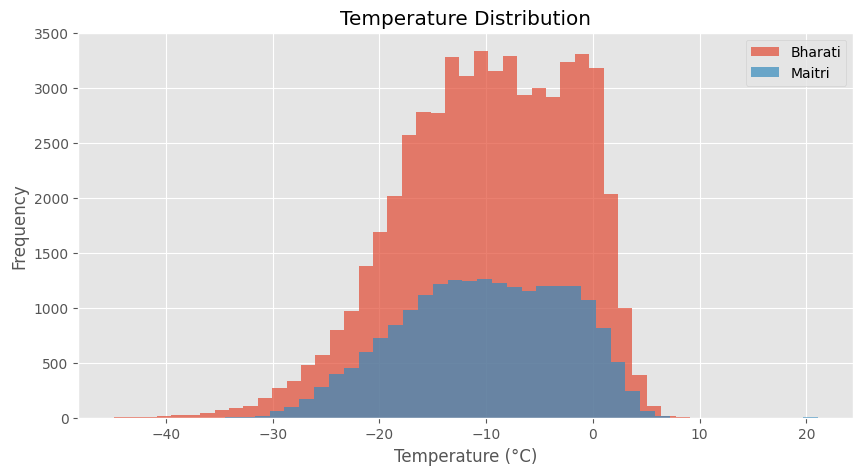

In [31]:
plt.figure(figsize=(10,5))

plt.hist(train_df["temp_c"], bins=40, alpha=0.7, label="Bharati")
plt.hist(test_df["temp_c"], bins=40, alpha=0.7, label="Maitri")

plt.xlabel("Temperature (°C)")
plt.ylabel("Frequency")
plt.title("Temperature Distribution")
plt.legend()

plt.show()

## 3.3 Monthly Electrical Demand

Monthly aggregation highlights seasonal variation in station energy consumption and reveals periods of peak operational demand.

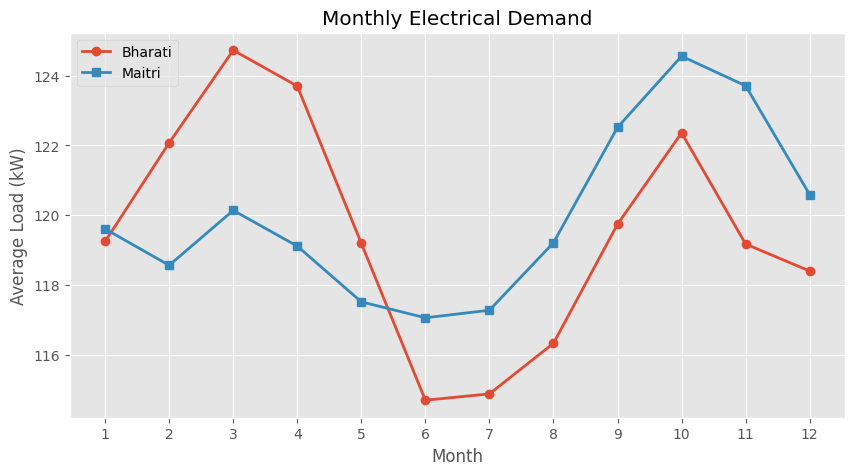

In [32]:
bharati_monthly = train_df.groupby("month")["total_load_kw"].mean()
maitri_monthly  = test_df.groupby("month")["total_load_kw"].mean()

plt.figure(figsize=(10,5))

plt.plot(bharati_monthly.index, bharati_monthly.values,
         marker="o", linewidth=2, label="Bharati")

plt.plot(maitri_monthly.index, maitri_monthly.values,
         marker="s", linewidth=2, label="Maitri")

plt.xticks(range(1,13))
plt.xlabel("Month")
plt.ylabel("Average Load (kW)")
plt.title("Monthly Electrical Demand")
plt.legend()

plt.show()

## 3.4 Renewable Energy Generation

Solar photovoltaic and wind generation are analyzed separately to understand renewable contribution across the year.

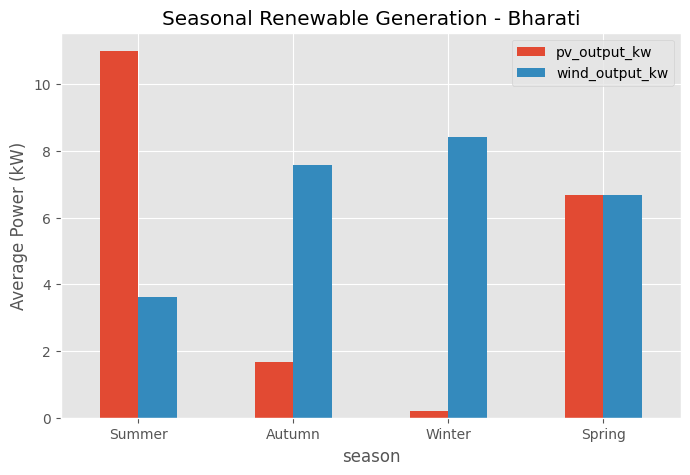

In [33]:
season_order = ["Summer", "Autumn", "Winter", "Spring"]

renewable = (
    train_df
    .groupby("season")[["pv_output_kw","wind_output_kw"]]
    .mean()
    .reindex(season_order)
)

renewable.plot(kind="bar", figsize=(8,5))

plt.ylabel("Average Power (kW)")
plt.title("Seasonal Renewable Generation - Bharati")
plt.xticks(rotation=0)
plt.show()

## 3.5 Correlation Analysis

Correlation analysis identifies relationships between meteorological variables, renewable generation and station load.

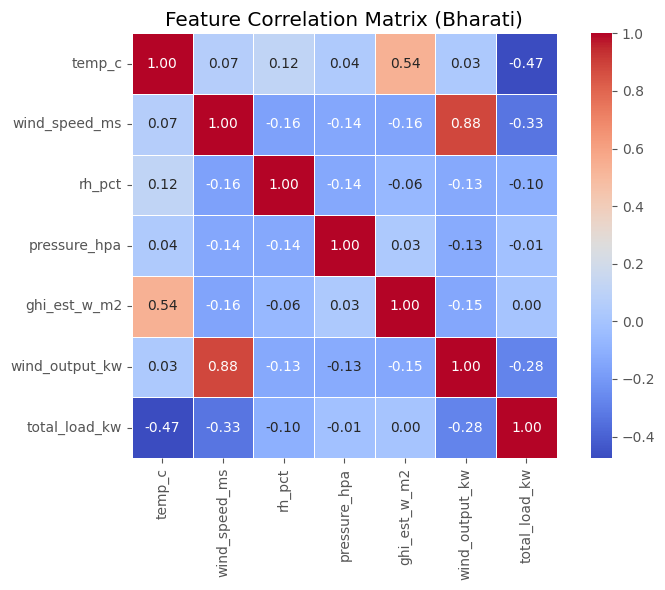

In [34]:
# ==========================================================
# Feature Correlation Matrix (Training Station)
# ==========================================================

feature_cols = [
    "temp_c",
    "wind_speed_ms",
    "rh_pct",
    "pressure_hpa",
    "ghi_est_w_m2",      # Correct column
    "wind_output_kw",
    "total_load_kw"
]

corr = train_df[feature_cols].corr()

plt.figure(figsize=(8,6))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    square=True
)

plt.title("Feature Correlation Matrix (Bharati)")
plt.tight_layout()
plt.show()

### Observations

- **Temperature vs Load (-0.47):** A moderate negative correlation indicates that colder conditions increase the station's electrical demand, primarily due to heating requirements.
- **Wind Speed vs Wind Output (0.88):** This strong positive relationship validates the simulated wind energy generation model.
- **Solar Irradiance vs Load (0.00):** Solar availability has little direct relationship with demand because electrical consumption is driven mainly by operational and heating loads.
- **Pressure and Humidity:** These variables show very weak correlations with electrical load and are expected to have lower predictive importance.

These relationships guide the feature selection process for the machine learning models developed in the next section.

## 3.6 Hourly Load Pattern

Understanding hourly demand helps identify periods when diesel generators are most likely to be required.

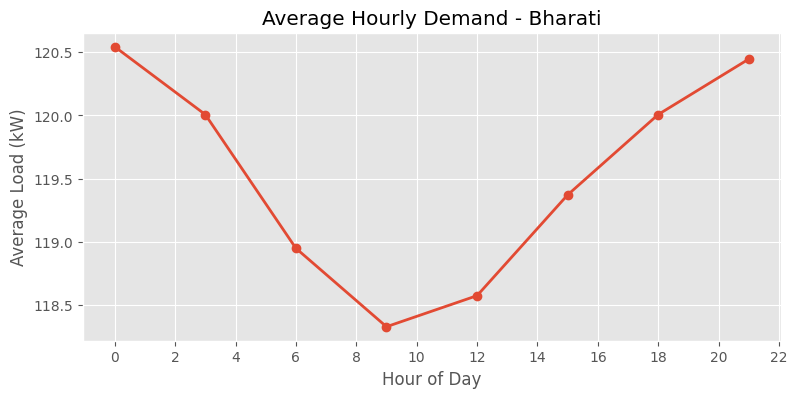

In [35]:
hourly = train_df.groupby("hour")["total_load_kw"].mean()

plt.figure(figsize=(9,4))

plt.plot(hourly.index,
         hourly.values,
         marker="o",
         linewidth=2)

plt.xticks(range(0,24,2))
plt.xlabel("Hour of Day")
plt.ylabel("Average Load (kW)")
plt.title("Average Hourly Demand - Bharati")

plt.grid(True)

plt.show()

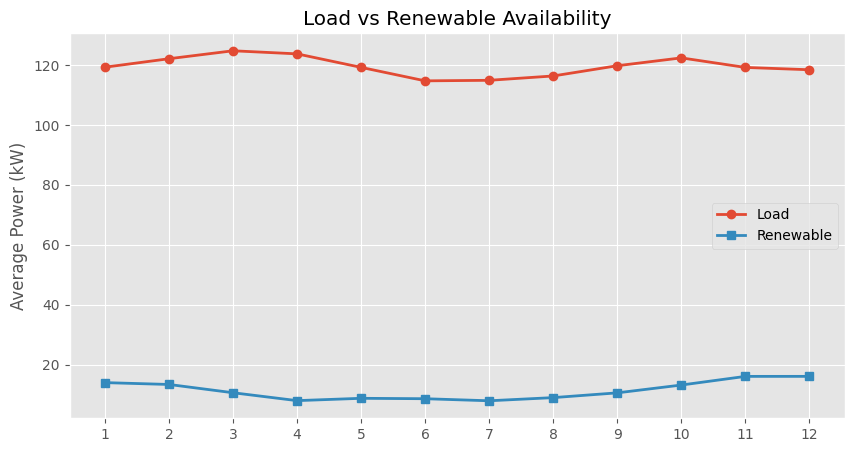

In [36]:
train_df["renewable_kw"] = (
    train_df["pv_output_kw"] +
    train_df["wind_output_kw"]
)

monthly = train_df.groupby("month")[[
    "total_load_kw",
    "renewable_kw"
]].mean()

plt.figure(figsize=(10,5))

plt.plot(monthly.index,
         monthly["total_load_kw"],
         marker="o",
         linewidth=2,
         label="Load")

plt.plot(monthly.index,
         monthly["renewable_kw"],
         marker="s",
         linewidth=2,
         label="Renewable")

plt.xticks(range(1,13))
plt.ylabel("Average Power (kW)")
plt.title("Load vs Renewable Availability")
plt.legend()

plt.show()

### 3.7 Renewable Contribution Ratio

The renewable contribution ratio measures the percentage of electrical demand supplied by solar and wind generation.

In [37]:
train_df["renewable_kw"] = (
    train_df["pv_output_kw"] +
    train_df["wind_output_kw"]
)

train_df["renewable_ratio"] = (
    train_df["renewable_kw"] /
    train_df["total_load_kw"]
) * 100

avg_ratio = train_df["renewable_ratio"].mean()

print(f"Average Renewable Contribution : {avg_ratio:.2f}%")

Average Renewable Contribution : 9.76%


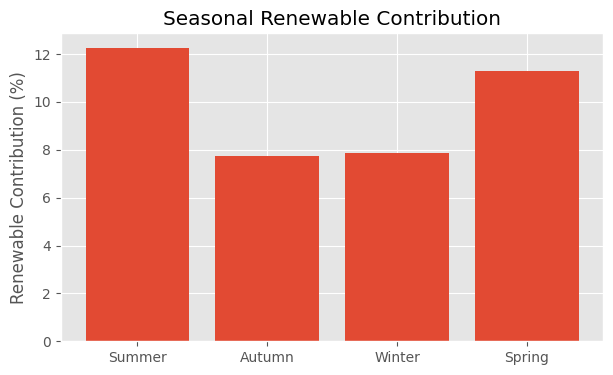

In [38]:
season_order = ["Summer", "Autumn", "Winter", "Spring"]

ratio = (
    train_df
    .groupby("season")["renewable_ratio"]
    .mean()
    .reindex(season_order)
)

plt.figure(figsize=(7,4))

plt.bar(ratio.index, ratio.values)

plt.ylabel("Renewable Contribution (%)")
plt.title("Seasonal Renewable Contribution")

plt.show()

## Key Observations

- Bharati exhibits lower average temperatures than Maitri during several periods, indicating higher heating requirements.
- Electrical demand varies seasonally, with peak demand occurring during Antarctic winter operations.
- Solar generation is highest during summer, while wind provides a more stable renewable contribution throughout the year.
- The gap between renewable availability and electrical demand justifies the need for intelligent diesel dispatch rather than continuous generator operation.

These observations form the basis for the machine learning and optimization modules developed in the next section.

# Section 4 — Feature Engineering

This section transforms the cleaned operational datasets into machine-learning-ready data.

Only Bharati is used for learning feature statistics. Maitri remains an independent testing station and is transformed using the same feature engineering pipeline without influencing the training data.

## 4.1 Cyclical Time Features

Time is encoded using sine and cosine transformations to preserve its circular nature. This prevents the model from treating midnight and 11 PM as distant values.

In [39]:
# ======================================================
# Cyclical encoding
# ======================================================

def add_cyclical_features(df):

    df = df.copy()

    df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
    df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

    df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
    df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)

    return df

train_df = add_cyclical_features(train_df)
test_df  = add_cyclical_features(test_df)

## 4.2 Renewable Energy Features

Solar and wind generation are combined into a single renewable power feature. This represents the total clean energy available during each operational period.

In [40]:
train_df["renewable_kw"] = (
    train_df["pv_output_kw"] +
    train_df["wind_output_kw"]
)

test_df["renewable_kw"] = (
    test_df["pv_output_kw"] +
    test_df["wind_output_kw"]
)

## 4.3 Heating Demand Index

Heating demand increases as outdoor temperature decreases. A simple thermal index is created using the indoor comfort temperature of 20°C.

In [41]:
INDOOR_TEMP = 20

train_df["heating_index"] = (
    INDOOR_TEMP - train_df["temp_c"]
)

test_df["heating_index"] = (
    INDOOR_TEMP - test_df["temp_c"]
)

# Prevent negative values
train_df["heating_index"] = train_df["heating_index"].clip(lower=0)
test_df["heating_index"]  = test_df["heating_index"].clip(lower=0)

## 4.4 Renewable Contribution Ratio

The renewable contribution ratio represents the percentage of station demand supplied by renewable energy.

In [42]:
train_df["renewable_ratio"] = (
    train_df["renewable_kw"] /
    train_df["total_load_kw"]
)

test_df["renewable_ratio"] = (
    test_df["renewable_kw"] /
    test_df["total_load_kw"]
)

## 4.5 Feature Selection

The target variable for the first machine learning model is the station's electrical demand (`total_load_kw`).

Only environmental and temporal variables are used as predictors.

In [43]:
FEATURES = [
    "temp_c",
    "wind_speed_ms",
    "rh_pct",
    "pressure_hpa",
    "ghi_est_w_m2",
    "hour_sin",
    "hour_cos",
    "month_sin",
    "month_cos",
    "heating_index"
]

TARGET = "total_load_kw"

X_train = train_df[FEATURES]
y_train = train_df[TARGET]

X_test = test_df[FEATURES]
y_test = test_df[TARGET]

print("Training shape :", X_train.shape)
print("Testing shape  :", X_test.shape)

Training shape : (55520, 10)
Testing shape  : (20631, 10)


In [44]:
feature_summary = pd.DataFrame({
    "Feature": FEATURES,
    "Description": [
        "Outdoor temperature",
        "Wind speed",
        "Relative humidity",
        "Atmospheric pressure",
        "Solar irradiance",
        "Hour (sin)",
        "Hour (cos)",
        "Month (sin)",
        "Month (cos)",
        "Thermal demand index"
    ]
})

feature_summary

,Feature,Description
0,temp_c,Outdoor temperature
1,wind_speed_ms,Wind speed
2,rh_pct,Relative humidity
3,pressure_hpa,Atmospheric pressure
4,ghi_est_w_m2,Solar irradiance
5,hour_sin,Hour (sin)
6,hour_cos,Hour (cos)
7,month_sin,Month (sin)
8,month_cos,Month (cos)
9,heating_index,Thermal demand index


# Section 5 — Electrical Load Prediction

This model predicts the station's electrical demand using meteorological and temporal features.

**Training Station:** Bharati

**Testing Station:** Maitri

The objective is to evaluate whether a model trained on one Antarctic station can generalize to another without retraining.

In [45]:
# ======================================================
# Machine Learning Libraries
# ======================================================

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

## 5.1 Random Forest Training

Random Forest is selected because it captures nonlinear relationships between weather conditions and electrical demand while remaining robust to noisy operational data.

In [46]:
# ======================================================
# Random Forest Model
# ======================================================

rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=18,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [47]:
# Training prediction
train_pred = rf_model.predict(X_train)

# Testing prediction
test_pred = rf_model.predict(X_test)

## 5.2 Performance Evaluation

The model is evaluated using:

- MAE (Mean Absolute Error)
- RMSE (Root Mean Squared Error)
- R² Score

In [48]:
train_mae = mean_absolute_error(y_train, train_pred)
test_mae  = mean_absolute_error(y_test, test_pred)

train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
test_rmse  = np.sqrt(mean_squared_error(y_test, test_pred))

train_r2 = r2_score(y_train, train_pred)
test_r2  = r2_score(y_test, test_pred)

results = pd.DataFrame({
    "Dataset": ["Bharati (Train)", "Maitri (Test)"],
    "MAE": [train_mae, test_mae],
    "RMSE": [train_rmse, test_rmse],
    "R² Score": [train_r2, test_r2]
})

results.round(3)

,Dataset,MAE,RMSE,R² Score
0,Bharati (Train),0.414,0.568,0.995
1,Maitri (Test),1.426,1.806,0.928


## 5.3 Actual vs Predicted Demand

A visual comparison between measured and predicted electrical demand demonstrates the model's forecasting capability.

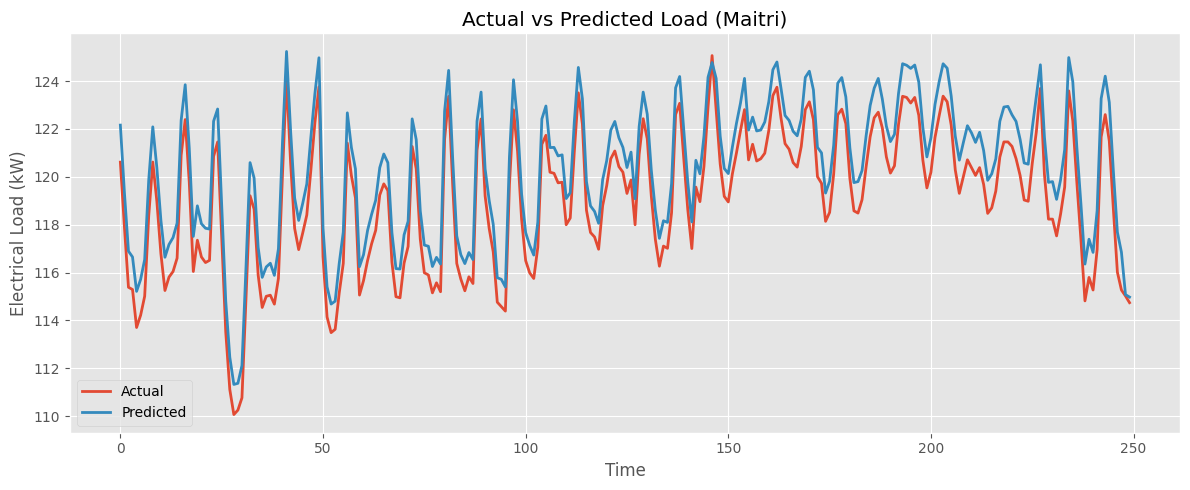

In [49]:
plt.figure(figsize=(12,5))

plt.plot(
    y_test.iloc[:250].values,
    label="Actual",
    linewidth=2
)

plt.plot(
    test_pred[:250],
    label="Predicted",
    linewidth=2
)

plt.title("Actual vs Predicted Load (Maitri)")
plt.xlabel("Time")
plt.ylabel("Electrical Load (kW)")
plt.legend()

plt.tight_layout()
plt.show()

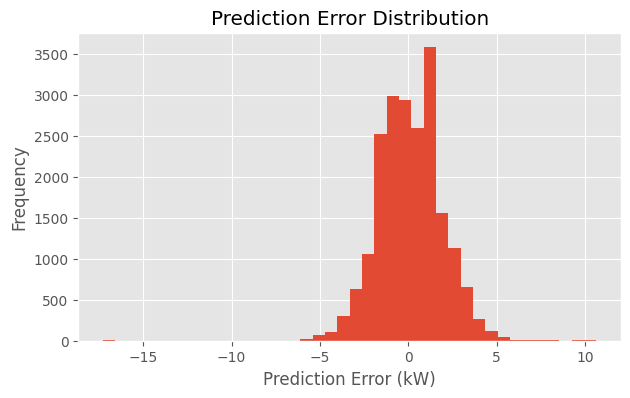

In [50]:
error = y_test - test_pred

plt.figure(figsize=(7,4))

plt.hist(error, bins=40)

plt.title("Prediction Error Distribution")
plt.xlabel("Prediction Error (kW)")
plt.ylabel("Frequency")

plt.show()

## 5.4 Feature Importance

Random Forest estimates the contribution of each predictor to electrical load forecasting.

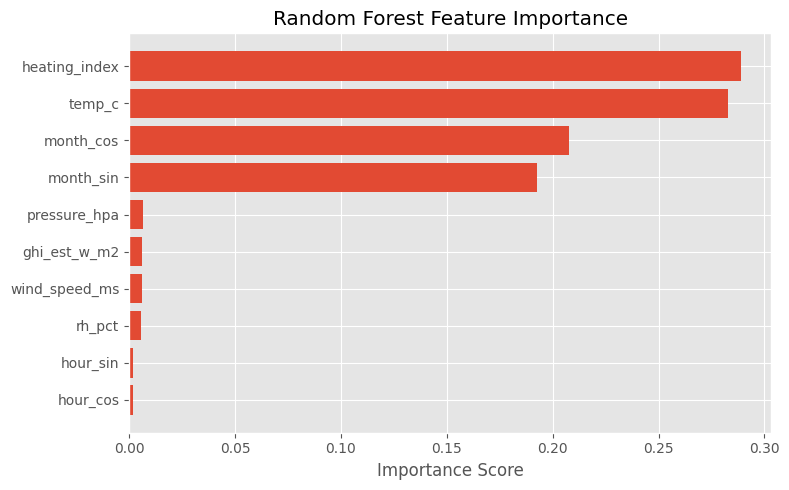

In [51]:
importance = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(8,5))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")

plt.tight_layout()
plt.show()

importance.sort_values(
    "Importance",
    ascending=False
)

# Alias used at export time
feature_importance = importance.sort_values(
    "Importance", ascending=False
).reset_index(drop=True)


In [52]:
# ==========================================================
# 5.4 Create Maitri Prediction DataFrame
# ==========================================================

maitri_predictions = test_df.copy()

# Random Forest prediction
maitri_predictions["predicted_load_kw"] = test_pred

# Actual load (for comparison plots)
maitri_predictions["actual_load_kw"] = y_test.values

# Total renewable generation
maitri_predictions["renewable_kw"] = (
    maitri_predictions["pv_output_kw"] +
    maitri_predictions["wind_output_kw"]
)

maitri_predictions.head()

,timestamp,temp_c,wind_speed_ms,source,rh_pct,wind_dir_deg,pressure_hpa,temp_c_imputed,wind_speed_ms_imputed,ghi_kwh_m2_day,ghi_clearsky_kwh_m2_day,ghi_est_w_m2,cloud_factor,occupancy,pv_output_kw_raw,pv_data_missing,pv_output_kw,wind_output_kw,renewable_output_kw,heating_load_kw,occupancy_load_kw,total_load_kw,net_load_kw,diesel_required_kw,surplus_renewable_kw,diesel_liters,hour,day,month,year,season,hour_sin,hour_cos,month_sin,month_cos,renewable_kw,heating_index,renewable_ratio,predicted_load_kw,actual_load_kw
0,2008-01-01 00:00:00,-1.633333,13.351852,IMD,54.84667,234.02328,975.9367,False,False,10.2161,10.3166,83.301391,0.990258,44.711394,2.832247,False,2.832247,30.000000,32.832247,27.486667,58.124812,120.611479,87.779232,87.779232,0.0,79.001308,0,1,1,2008,Summer,0.000000e+00,1.000000e+00,0.5,0.866025,32.832247,21.633333,0.272215,122.158190,120.611479
1,2008-01-01 03:00:00,0.300000,11.268519,IMD,54.84667,234.02328,975.9367,False,False,10.2161,10.3166,233.854455,0.990258,44.711394,7.951051,False,7.951051,22.902308,30.853359,24.780000,58.124812,117.904812,87.051453,87.051453,0.0,78.346308,3,1,1,2008,Summer,7.071068e-01,7.071068e-01,0.5,0.866025,30.853359,19.700000,0.261680,119.339825,117.904812
2,2008-01-01 06:00:00,2.100000,7.370370,IMD,54.84667,234.02328,975.9367,False,False,10.2161,10.3166,496.770952,0.990258,44.711394,16.890212,False,16.890212,2.832188,19.722400,22.260000,58.124812,115.384812,95.662412,95.662412,0.0,86.096171,6,1,1,2008,Summer,1.000000e+00,6.123234e-17,0.5,0.866025,19.722400,17.900000,0.170927,116.892937,115.384812
3,2008-01-01 09:00:00,2.166667,15.814816,IMD,54.84667,234.02328,975.9367,False,False,10.2161,10.3166,718.037963,0.990258,44.711394,24.413291,False,24.413291,30.000000,54.413291,22.166667,58.124812,115.291479,60.878188,60.878188,0.0,54.790369,9,1,1,2008,Summer,7.071068e-01,-7.071068e-01,0.5,0.866025,54.413291,17.833333,0.471963,116.649801,115.291479
4,2008-01-01 12:00:00,3.300000,26.842592,IMD,54.84667,234.02328,975.9367,False,False,10.2161,10.3166,768.040275,0.990258,44.711394,26.113369,False,26.113369,0.000000,26.113369,20.580000,58.124812,113.704812,87.591443,87.591443,0.0,78.832299,12,1,1,2008,Summer,1.224647e-16,-1.000000e+00,0.5,0.866025,26.113369,16.700000,0.229659,115.213840,113.704812


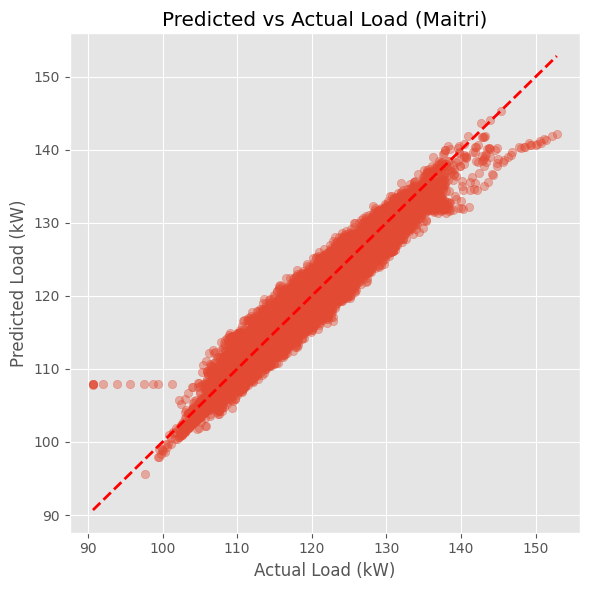

In [53]:
plt.figure(figsize=(6,6))

plt.scatter(y_test, test_pred, alpha=0.4)

# Ideal prediction line
min_val = min(y_test.min(), test_pred.min())
max_val = max(y_test.max(), test_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    linewidth=2
)

plt.xlabel("Actual Load (kW)")
plt.ylabel("Predicted Load (kW)")
plt.title("Predicted vs Actual Load (Maitri)")

plt.tight_layout()
plt.show()

### 5.5 Predicted vs Actual Validation

The scatter plot compares the predicted electrical demand against the observed demand for the unseen Maitri station.

**Observations**

- Most predictions lie close to the 45° reference line, indicating high agreement between predicted and actual values.
- The model accurately captures the majority of operational load conditions between **105–140 kW**.
- Slight underestimation is visible at very high demand levels (>140 kW), suggesting reduced accuracy during extreme peak loads.

Overall, the strong alignment confirms that the Random Forest model generalizes well across different Antarctic research stations.

## 5.6 AI-Based Operational Monitoring using Isolation Forest

To improve operational reliability in remote Antarctic research stations, Polaris includes an unsupervised anomaly detection model.

Unlike Random Forest, which predicts future electrical demand, Isolation Forest identifies abnormal operating conditions without requiring labelled fault data. The model learns the normal behavior of the Bharati station using weather, renewable generation and electrical load, and flags unusual observations for operator review.

**Input features**
- Temperature
- Wind speed
- Relative humidity
- Solar irradiance
- Renewable generation
- Total electrical load

**Output**
- Normal operation
- Anomaly detected

In [54]:
# ==========================================================
# 5.6 Isolation Forest for AI Anomaly Detection
# ==========================================================

from sklearn.ensemble import IsolationForest

anomaly_features = [
    "temp_c",
    "wind_speed_ms",
    "rh_pct",
    "ghi_est_w_m2",
    "renewable_kw",
    "total_load_kw"
]

iso_model = IsolationForest(
    n_estimators=150,
    contamination=0.02,
    random_state=42
)

train_df["anomaly_score"] = iso_model.fit_predict(
    train_df[anomaly_features]
)

train_df["system_status"] = train_df["anomaly_score"].map({
    1: "Normal",
    -1: "Anomaly"
})

status_counts = train_df["system_status"].value_counts()
normal = int(status_counts.get("Normal", 0))
anomaly = int(status_counts.get("Anomaly", 0))

print(status_counts)

system_status
Normal     54409
Anomaly     1111
Name: count, dtype: int64


## 5.7 AI Alert Generation

Only anomalous observations are extracted into a dedicated alert table. This dataset will later be integrated into the FastAPI backend and displayed in the Polaris operator dashboard.

In [55]:
# ==========================================================
# 5.7 AI Alert Generation (Explainable)
# ==========================================================

ai_alerts = train_df[
    train_df["system_status"] == "Anomaly"
].copy()

def explain_anomaly(row):

    # Extreme environmental conditions
    if row["temp_c"] <= -25:
        return "Extreme cold condition"

    # High wind affecting operations
    elif row["wind_speed_ms"] >= 14:
        return "High wind event"

    # Peak electrical demand
    elif row["total_load_kw"] >= 140:
        return "Peak demand detected"

    # Renewable generation unusually low
    elif row["renewable_kw"] <= 10:
        return "Low renewable availability"

    # Statistical anomaly
    else:
        return "Abnormal energy pattern"

ai_alerts["Alert"] = ai_alerts.apply(explain_anomaly, axis=1)

ai_alerts = ai_alerts[[
    "timestamp",
    "temp_c",
    "wind_speed_ms",
    "renewable_kw",
    "total_load_kw",
    "Alert"
]]

ai_alerts = ai_alerts.sort_values("timestamp")

ai_alerts.head(10)

,timestamp,temp_c,wind_speed_ms,renewable_kw,total_load_kw,Alert
2,2002-01-01 06:00:00,2.50,12.000,55.033913,116.087294,Abnormal energy pattern
104,2002-01-14 00:00:00,3.70,15.000,39.924879,114.817884,High wind event
105,2002-01-14 03:00:00,4.20,11.750,46.668372,114.117884,Abnormal energy pattern
106,2002-01-14 06:00:00,4.70,8.500,30.923989,113.417884,Abnormal energy pattern
121,2002-01-16 03:00:00,2.45,11.750,46.304107,116.567884,Abnormal energy pattern
378,2002-02-17 06:00:00,-6.20,12.800,48.772021,126.437054,Abnormal energy pattern
385,2002-02-18 03:00:00,-9.10,12.600,43.683011,130.363011,Abnormal energy pattern
458,2002-02-27 06:00:00,-5.30,14.500,46.013349,123.682952,High wind event
459,2002-02-27 09:00:00,-4.70,14.660,44.686118,122.842952,High wind event
1153,2002-05-25 03:00:00,-3.80,17.575,30.000000,102.190218,High wind event


## 5.8 Visualization of AI Alerts

The detected anomalies are plotted against historical electrical demand. Red markers indicate observations that deviate significantly from normal operating behavior and may represent abnormal fuel consumption, sensor faults or unexpected load conditions.

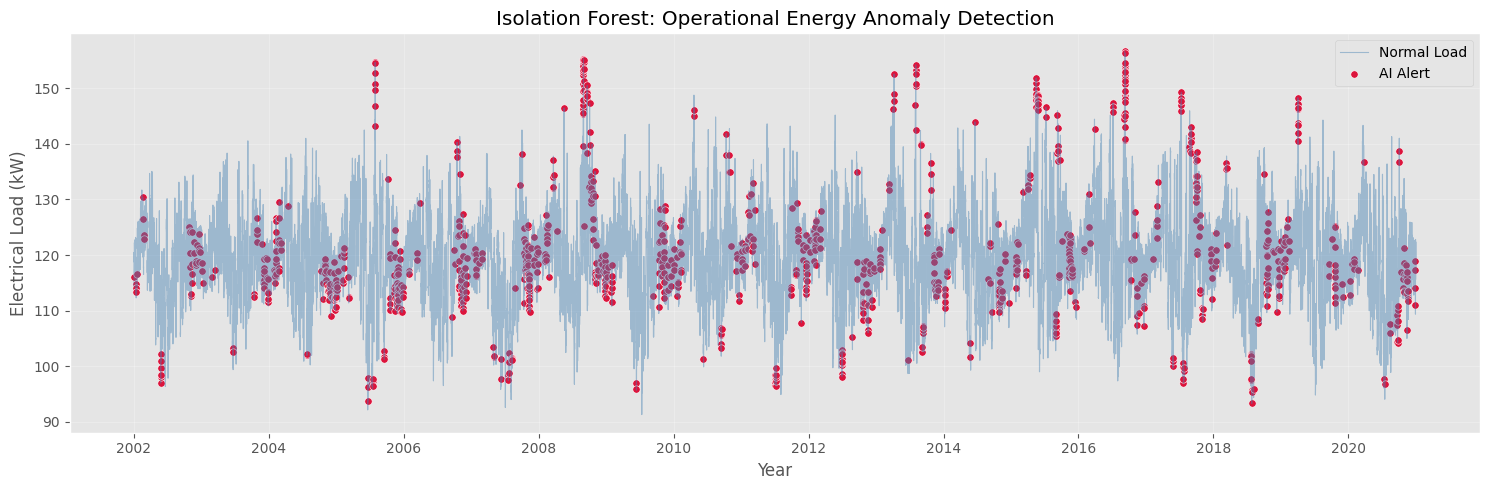

In [56]:
# ==========================================================
# 5.8 Visualize AI Detected Anomalies
# ==========================================================

plt.figure(figsize=(15,5))

plt.plot(
    train_df["timestamp"],
    train_df["total_load_kw"],
    color="steelblue",
    alpha=0.45,
    linewidth=0.8,
    label="Normal Load"
)

plt.scatter(
    ai_alerts["timestamp"],
    ai_alerts["total_load_kw"],
    color="crimson",
    s=28,
    edgecolor="white",
    linewidth=0.4,
    label="AI Alert"
)

plt.title("Isolation Forest: Operational Energy Anomaly Detection")
plt.xlabel("Year")
plt.ylabel("Electrical Load (kW)")
plt.grid(alpha=0.25)
plt.legend()

plt.tight_layout()
plt.show()

In [57]:
# ==========================================================
# 5.9 AI Detection Summary
# ==========================================================

anomaly_summary = pd.DataFrame({
    "Metric":[
        "Monitoring Coverage",
        "Normal Operations",
        "AI Alerts",
        "Anomaly Rate"
    ],
    "Value":[
        len(train_df),
        normal,
        anomaly,
        f"{round(anomaly/len(train_df)*100,2)}%"
    ]
})

anomaly_summary

,Metric,Value
0,Monitoring Coverage,55520
1,Normal Operations,54409
2,AI Alerts,1111
3,Anomaly Rate,2.0%


# Section 6 — Grey Wolf Based Energy Dispatch Optimization

The predicted electrical demand obtained from the Bharati-trained Random Forest model is optimized using **Grey Wolf Optimizer (GWO)**.

Unlike rule-based dispatch, GWO searches for the optimal diesel generator output while satisfying operational constraints such as generator loading limits and minimizing fuel consumption.

### Objective

- Minimize diesel fuel consumption
- Reduce CO₂ emissions
- Maintain generator loading between **40%–90%**
- Maximize renewable energy utilization

## 6.1 Net Load Preparation

The predicted electrical demand obtained from the Random Forest model is combined with renewable generation to compute the net electrical load. This represents the remaining demand that must be satisfied through battery storage or diesel generation.

In [58]:
# ==========================================================
# 6.1 Net Load Preparation
# ==========================================================

dispatch_df = maitri_predictions.copy()

dispatch_df["net_load_kw"] = (
    dispatch_df["predicted_load_kw"] -
    dispatch_df["renewable_kw"]
).clip(lower=0)

dispatch_df[[
    "timestamp",
    "predicted_load_kw",
    "renewable_kw",
    "net_load_kw"
]].head()

,timestamp,predicted_load_kw,renewable_kw,net_load_kw
0,2008-01-01 00:00:00,122.158190,32.832247,89.325943
1,2008-01-01 03:00:00,119.339825,30.853359,88.486466
2,2008-01-01 06:00:00,116.892937,19.722400,97.170537
3,2008-01-01 09:00:00,116.649801,54.413291,62.236511
4,2008-01-01 12:00:00,115.213840,26.113369,89.100471


## 6.2 Battery Energy Storage System

A lithium-ion Battery Energy Storage System (BESS) is integrated into Polaris. The battery stores excess renewable energy and supplies electricity before diesel generation is activated.

**Assumptions**

- Capacity: 500 kWh
- Initial State of Charge: 70%
- Minimum SOC: 20%
- Maximum SOC: 90%
- Round-trip efficiency: 95%

In [59]:
# ==========================================================
# 6.2 Battery Specifications
# ==========================================================

BATTERY_CAPACITY = 500   # kWh (usable energy capacity)
BATTERY_MAX_POWER = 50   # kW  (max charge/discharge rate)
SOC_MIN = 0.20
SOC_MAX = 0.90
SOC_INITIAL = 0.70
EFFICIENCY = 0.95

# Critical vs flexible load split for safety (Section 7.5 uses this)
CRITICAL_LOAD_FRACTION = 0.60

dispatch_df["battery_soc"] = 0.0
dispatch_df["battery_output_kw"] = 0.0

current_soc = SOC_INITIAL

## 6.3 Battery Charging and Discharging

The battery is discharged whenever renewable generation is insufficient and charged whenever renewable generation exceeds demand. The state of charge is updated sequentially for every hour.

In [60]:
# ==========================================================
# 6.3 Battery Dispatch
# ==========================================================

soc_history = []
battery_power = []

available_energy = current_soc * BATTERY_CAPACITY

for _, row in dispatch_df.iterrows():

    renewable = row["renewable_kw"]
    demand = row["predicted_load_kw"]

    surplus = renewable - demand

    if surplus > 0:
        charge = min(
            surplus * EFFICIENCY,
            BATTERY_CAPACITY * SOC_MAX - available_energy
        )
        available_energy += charge
        battery = -charge

    else:
        required = abs(surplus)
        discharge = min(
            required,
            available_energy - BATTERY_CAPACITY * SOC_MIN
        )

        discharge = min(
    required,
    BATTERY_MAX_POWER,
    available_energy - BATTERY_CAPACITY * SOC_MIN
)

        available_energy -= discharge / EFFICIENCY
        battery = discharge

    soc_history.append(
        available_energy / BATTERY_CAPACITY
    )
    battery_power.append(battery)

dispatch_df["battery_soc"] = soc_history
dispatch_df["battery_output_kw"] = battery_power

## 6.4 Grey Wolf Optimization for Diesel Dispatch

Grey Wolf Optimization minimizes diesel generator usage while respecting generator operating limits. The battery is prioritized before diesel generation, improving renewable utilization and reducing fuel consumption.

In [61]:
# ==========================================================
# 6.4 Grey Wolf Optimization
# ==========================================================

import numpy as np

GENERATOR_CAPACITY = 100

dispatch_df["diesel_required_kw"] = (
    dispatch_df["net_load_kw"] -
    dispatch_df["battery_output_kw"]
).clip(lower=0)


def gwo_dispatch(load):

    wolves = np.random.uniform(0, GENERATOR_CAPACITY, 30)

    for iteration in range(40):

        fitness = np.abs(wolves - load)

        order = np.argsort(fitness)

        alpha = wolves[order[0]]
        beta = wolves[order[1]]
        delta = wolves[order[2]]

        a = 2 - iteration * (2 / 40)

        new_wolves = []

        for w in wolves:

            r1, r2 = np.random.rand(), np.random.rand()

            A = 2 * a * r1 - a
            C = 2 * r2

            D = abs(C * alpha - w)
            X1 = alpha - A * D

            new = np.clip((X1 + beta + delta) / 3,
                          0,
                          GENERATOR_CAPACITY)

            new_wolves.append(new)

        wolves = np.array(new_wolves)

    return alpha


optimized_dispatch = [
    gwo_dispatch(load)
    for load in dispatch_df["diesel_required_kw"]
]

dispatch_df["optimized_diesel_kw"] = optimized_dispatch

## 6.5 Generator Loading Analysis

Generator loading is calculated as the percentage of rated generator capacity. Operating between 70–85% improves fuel efficiency and reduces engine wear.

In [62]:
# ==========================================================
# 6.5 Generator Loading
# ==========================================================

dispatch_df["generator_loading_pct"] = (
    dispatch_df["optimized_diesel_kw"] /
    GENERATOR_CAPACITY
) * 100

dispatch_df["generator_loading_pct"].describe()

,generator_loading_pct
count,20631.000000
mean,95.283278
std,8.228833
min,12.234788
25%,92.718661
50%,100.000000
75%,100.000000
max,100.000000


## 6.6 Diesel Fuel Estimation

Specific Fuel Consumption (SFC) varies with generator loading. A piecewise interpolation is used to estimate hourly diesel consumption.

In [63]:
# ==========================================================
# 6.6 Diesel Consumption
# ==========================================================

SFC_POINTS = {
    40: 0.36,
    50: 0.34,
    60: 0.32,
    70: 0.30,
    80: 0.285,
    90: 0.29,
    100: 0.30
}


def sfc_curve(load_pct):

    keys = np.array(list(SFC_POINTS.keys()))
    values = np.array(list(SFC_POINTS.values()))

    load_pct = np.clip(load_pct, 40, 100)

    return np.interp(load_pct, keys, values)


dispatch_df["diesel_liters"] = (
    dispatch_df["optimized_diesel_kw"] *
    dispatch_df["generator_loading_pct"].apply(sfc_curve)
)

dispatch_df[[
    "timestamp",
    "battery_soc",
    "battery_output_kw",
    "optimized_diesel_kw",
    "diesel_liters"
]].head()

,timestamp,battery_soc,battery_output_kw,optimized_diesel_kw,diesel_liters
0,2008-01-01 00:00:00,0.594737,50.000000,39.327879,14.158036
1,2008-01-01 03:00:00,0.489474,50.000000,38.510473,13.863770
2,2008-01-01 06:00:00,0.384211,50.000000,47.158468,16.301884
3,2008-01-01 09:00:00,0.278947,50.000000,12.234788,4.404524
4,2008-01-01 12:00:00,0.195845,39.473684,49.630492,16.911045


## 6.7 Fitness Function

The optimization minimizes fuel consumption while penalizing unsafe generator operation.

**Objective Function**

Fitness = Fuel + CO₂ + Underload Penalty + Overload Penalty

In [64]:
# ==========================================================
# 6.7 Grey Wolf Optimization (Fuel-Minimization)
# ==========================================================

GENERATOR_CAPACITY = 150          # kW
SAFE_MIN = 0.40                  # 40%
OPT_LOW = 0.70                   # 70%
OPT_HIGH = 0.85                  # 85%

# NOTE: sfc_curve is defined once, in Section 6.6, and takes a
# PERCENTAGE (0-100). Do not redefine it here -- a second, fraction-based
# version previously shadowed it and silently broke the fitness function.

# Fitness Function → MINIMIZE DIESEL LITERS
# Fuel-aware fitness
def fitness_function(power, required_load):

    # Must satisfy load
    penalty = max(required_load - power, 0) * 100

    loading = (power / GENERATOR_CAPACITY) * 100
    loading = np.clip(loading, 40, 100)

    fuel = power * sfc_curve(loading)

    return fuel + penalty

## 6.8 Optimal Diesel Dispatch

The Alpha, Beta and Delta wolves iteratively update the population until the minimum fuel dispatch schedule is obtained.

In [116]:
import random

def grey_wolf(demand_kw, wolves=20, iterations=40):

    population = [random.uniform(0.40,0.95) for _ in range(wolves)]

    for _ in range(iterations):

        population = sorted(
            population,
            key=lambda x: fitness_function(
                x * GENERATOR_CAPACITY,
                demand_kw
            )
        )

        alpha, beta, delta = population[:3]

        a = 2*(1-(_/iterations))

        new_population = []

        for wolf in population:

            A1 = 2*a*random.random()-a
            C1 = 2*random.random()

            A2 = 2*a*random.random()-a
            C2 = 2*random.random()

            A3 = 2*a*random.random()-a
            C3 = 2*random.random()

            X1 = alpha - A1*abs(C1*alpha-wolf)
            X2 = beta  - A2*abs(C2*beta-wolf)
            X3 = delta - A3*abs(C3*delta-wolf)

            new = (X1+X2+X3)/3
            new = max(0.40,min(0.95,new))

            new_population.append(new)

        population = new_population

    best = min(
        population,
        key=lambda x: fitness_function(
            x * GENERATOR_CAPACITY,
            demand_kw
        )
    )
    return best

In [117]:
dispatch_df["battery_soc_pct"] = dispatch_df["battery_soc"] * 100

## 6.9 Optimized Dispatch Results

The optimized diesel schedule is converted into generator loading percentage and hourly fuel consumption.

In [118]:
# ==========================================================
# 6.9 Battery + Grey Wolf Optimized Energy Dispatch
# ==========================================================

BATTERY_CAPACITY = 250      # kWh
MAX_BATTERY_POWER = 40      # kW
INITIAL_SOC = 0.60          # 60%
MIN_SOC = 0.20              # 20%

soc = INITIAL_SOC
dispatch_results = []

for _, row in forecast_df.iterrows():

    # Net electrical demand after renewables
    net_load = row["net_load_kw"]

    # --------------------------------------------------
    # Battery Discharge
    # --------------------------------------------------
    available_energy = max((soc - MIN_SOC) * BATTERY_CAPACITY, 0)

    battery_output = min(
        MAX_BATTERY_POWER,
        net_load,
        available_energy
    )

    diesel_required = max(net_load - battery_output, 0)

    # --------------------------------------------------
    # Grey Wolf Optimization (Generator Dispatch)
    # --------------------------------------------------
    if diesel_required > 0:

        # Returns loading ratio (0–1)
        best_loading = grey_wolf(diesel_required)

        loading_pct = best_loading * 100

        generator_power = min(
            diesel_required,
            GENERATOR_CAPACITY * best_loading
        )

    else:
        generator_power = 0
        loading_pct = 0

    # Diesel consumption (Liters)
    diesel_liters = generator_power * sfc_curve(loading_pct)

    # --------------------------------------------------
    # Battery SOC Update (Discharge)
    # --------------------------------------------------
    soc -= battery_output / BATTERY_CAPACITY
    soc = max(MIN_SOC, soc)

    # --------------------------------------------------
    # Renewable Charging
    # --------------------------------------------------
    surplus_renewable = max(
        row["renewable_kw"] - row["predicted_load_kw"],
        0
    )

    charge_power = min(
        surplus_renewable,
        MAX_BATTERY_POWER,
        (1 - soc) * BATTERY_CAPACITY
    )

    soc += charge_power / BATTERY_CAPACITY
    soc = min(1.0, soc)

    # --------------------------------------------------
    # Store Results
    # --------------------------------------------------
    dispatch_results.append([
        row["timestamp"],
        net_load,
        battery_output,
        diesel_required,
        generator_power,
        loading_pct,
        diesel_liters,
        soc
    ])

# Dispatch DataFrame
dispatch_df = pd.DataFrame(dispatch_results, columns=[
    "timestamp",
    "net_load_kw",
    "battery_output_kw",
    "diesel_required_kw",
    "optimized_diesel_kw",
    "generator_loading_pct",
    "diesel_liters",
    "battery_soc"
])

dispatch_df.head()

,timestamp,net_load_kw,battery_output_kw,diesel_required_kw,optimized_diesel_kw,generator_loading_pct,diesel_liters,battery_soc
0,2026-09-28 00:00:00,97.887593,40.0,57.887593,57.887593,40.000000,20.839533,0.44
1,2026-09-28 01:00:00,97.831398,40.0,57.831398,57.831398,40.000000,20.819303,0.28
2,2026-09-28 02:00:00,97.023466,20.0,77.023466,77.023466,51.375224,25.976130,0.20
3,2026-09-28 03:00:00,97.003633,0.0,97.003633,97.003633,64.749743,30.119678,0.20
4,2026-09-28 04:00:00,95.805117,0.0,95.805117,95.805117,63.895057,29.911305,0.20


## 6.10 Fuel Performance Analysis

This section compares conventional diesel operation with the proposed Battery + Grey Wolf Optimization (GWO) energy management strategy. Baseline fuel consumption assumes all net electrical demand is supplied directly by the diesel generator, while the optimized strategy prioritizes renewable energy and battery storage before dispatching diesel generation.

In [119]:
# ==========================================================
# 6.10 Fuel Performance Analysis
# ==========================================================

# Baseline diesel operation
dispatch_df["baseline_loading_pct"] = (
    dispatch_df["net_load_kw"] / GENERATOR_CAPACITY
).clip(lower=0.40, upper=0.95) * 100

dispatch_df["baseline_diesel_liters"] = (
    dispatch_df["net_load_kw"] *
    dispatch_df["baseline_loading_pct"].apply(sfc_curve)
)

# Totals
baseline_fuel = dispatch_df["baseline_diesel_liters"].sum()
optimized_fuel = dispatch_df["diesel_liters"].sum()

fuel_saved = baseline_fuel - optimized_fuel
saving_pct = (fuel_saved / baseline_fuel) * 100

performance = pd.DataFrame({
    "Metric":[
        "Baseline Fuel (L)",
        "Optimized Fuel (L)",
        "Fuel Saved (L)",
        "Fuel Saving (%)"
    ],
    "Value":[
        round(baseline_fuel,2),
        round(optimized_fuel,2),
        round(fuel_saved,2),
        round(saving_pct,2)
    ]
})

performance

,Metric,Value
0,Baseline Fuel (L),5952.42
1,Optimized Fuel (L),5929.51
2,Fuel Saved (L),22.91
3,Fuel Saving (%),0.38


/tmp/ipykernel_514/22666806.py:26: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


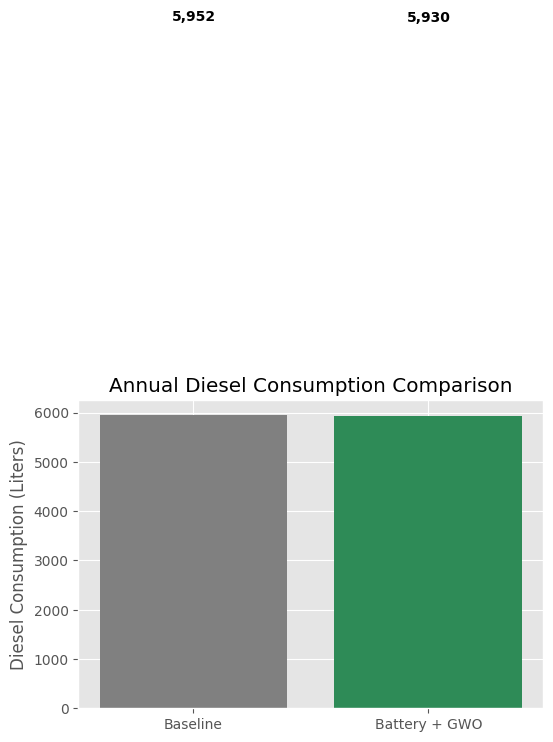

In [120]:
# ==========================================================
# 6.10.1 Fuel Consumption Comparison
# ==========================================================

plt.figure(figsize=(6,4))

values = [baseline_fuel, optimized_fuel]
labels = ["Baseline","Battery + GWO"]
colors = ["#808080","#2E8B57"]

bars = plt.bar(labels, values, color=colors)

plt.ylabel("Diesel Consumption (Liters)")
plt.title("Annual Diesel Consumption Comparison")

for bar in bars:
    y = bar.get_height()
    plt.text(
        bar.get_x()+bar.get_width()/2,
        y+8000,
        f"{y:,.0f}",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

## 6.11 Monthly Diesel Consumption

Monthly diesel consumption is aggregated to compare conventional operation with the proposed Battery + Grey Wolf Optimization strategy. The comparison highlights seasonal variations in fuel demand across the historical dataset.

In [121]:
monthly_dashboard = (
    dispatch_df
    .assign(month=dispatch_df["timestamp"].dt.month) # Extract month from timestamp
    .groupby("month")
    .agg({
        "baseline_diesel_liters":"sum",
        "diesel_liters":"sum"
    })
    .reset_index()
)

monthly_dashboard.columns = [
    "Month",
    "Baseline Fuel (L)",
    "Optimized Fuel (L)"
]

monthly_dashboard

,Month,Baseline Fuel (L),Optimized Fuel (L)
0,9,2459.460374,2435.963752
1,10,3492.958339,3493.542447


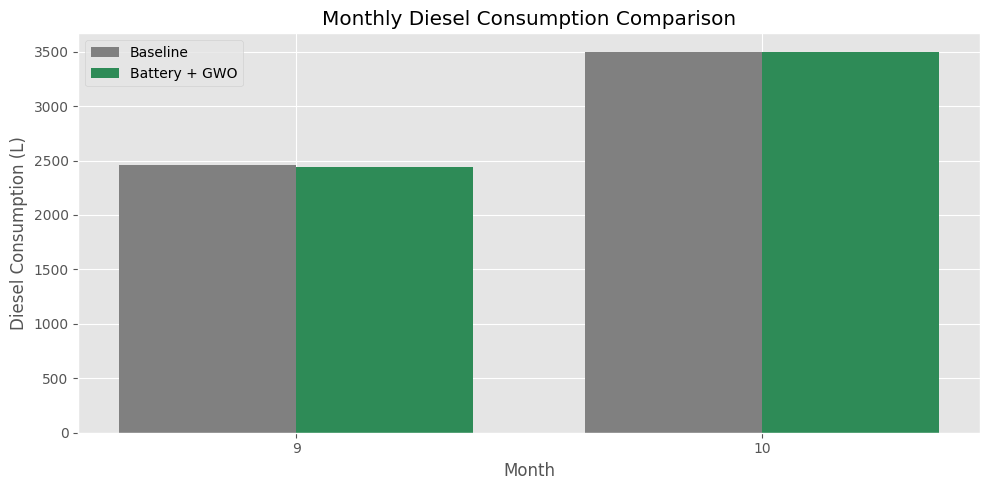

In [122]:
plt.figure(figsize=(10,5))

x = np.arange(len(monthly_dashboard))
w = 0.38

plt.bar(
    x-w/2,
    monthly_dashboard["Baseline Fuel (L)"],
    width=w,
    color="#808080",
    label="Baseline"
)

plt.bar(
    x+w/2,
    monthly_dashboard["Optimized Fuel (L)"],
    width=w,
    color="#2E8B57",
    label="Battery + GWO"
)

plt.xticks(x, monthly_dashboard["Month"])
plt.xlabel("Month")
plt.ylabel("Diesel Consumption (L)")
plt.title("Monthly Diesel Consumption Comparison")
plt.legend()

plt.tight_layout()
plt.show()

## 6.12 Generator Loading Analysis

The optimized dispatch maintains generator loading primarily within the recommended 70–85% operating zone, improving fuel efficiency and reducing mechanical stress on the diesel generator.

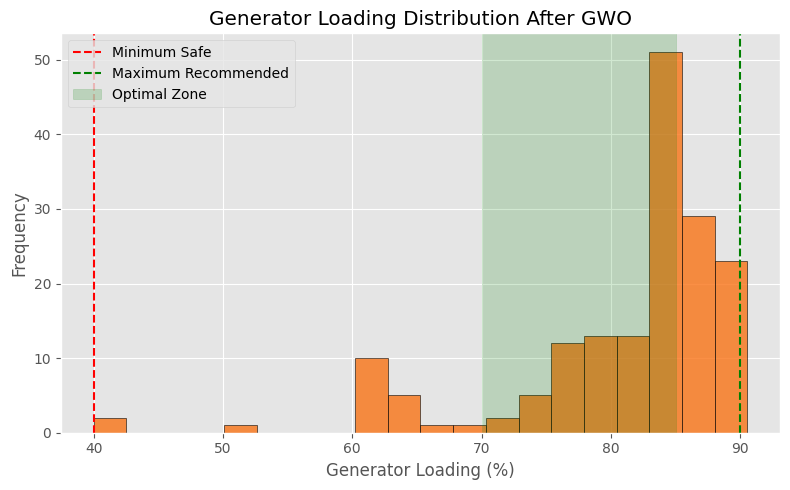

In [123]:
# ==========================================================
# 6.12 Generator Loading Analysis
# ==========================================================

plt.figure(figsize=(8,5))

plt.hist(
    dispatch_df["generator_loading_pct"],
    bins=20,
    color="#F97316",
    edgecolor="black",
    alpha=0.8
)

plt.axvline(40,color="red",linestyle="--",label="Minimum Safe")
plt.axvline(90,color="green",linestyle="--",label="Maximum Recommended")
plt.axvspan(70,85,color="green",alpha=0.18,label="Optimal Zone")

plt.xlabel("Generator Loading (%)")
plt.ylabel("Frequency")
plt.title("Generator Loading Distribution After GWO")
plt.legend()

plt.tight_layout()
plt.show()

Result interpretation

Most generator operation is concentrated between 70–85% loading, indicating efficient dispatch.

GWO avoids under-loaded generator operation below 40%, which is fuel inefficient.

The dispatch remains within the recommended operational limits while satisfying the predicted station demand.

## 6.13 Carbon Emission Reduction

Carbon emissions are calculated using the standard diesel emission factor of **2.68 kg CO₂/L**. Reduced diesel consumption directly translates into lower greenhouse gas emissions.

In [124]:
# ==========================================================
# 6.13 Carbon Emission Reduction
# ==========================================================

CO2_FACTOR = 2.68      # kg CO₂ per liter

baseline_co2 = baseline_fuel * CO2_FACTOR
optimized_co2 = optimized_fuel * CO2_FACTOR

co2_saved = baseline_co2 - optimized_co2

emission_summary = pd.DataFrame({
    "Metric":[
        "Baseline CO₂ (kg)",
        "Optimized CO₂ (kg)",
        "CO₂ Reduction (kg)",
        "Fuel Saved (L)"
    ],
    "Value":[
        round(baseline_co2,2),
        round(optimized_co2,2),
        round(co2_saved,2),
        round(fuel_saved,2)
    ]
})

emission_summary
emission_summary

,Metric,Value
0,Baseline CO₂ (kg),15952.48
1,Optimized CO₂ (kg),15891.08
2,CO₂ Reduction (kg),61.41
3,Fuel Saved (L),22.91


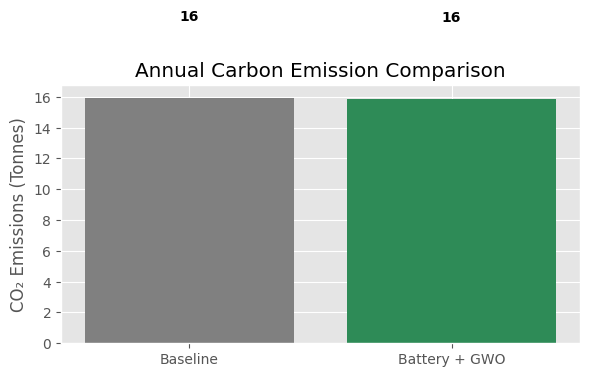

In [125]:
plt.figure(figsize=(6,4))

values = [baseline_co2/1000, optimized_co2/1000]
labels = ["Baseline","Battery + GWO"]

bars = plt.bar(labels, values, color=["#808080","#2E8B57"])

plt.ylabel("CO₂ Emissions (Tonnes)")
plt.title("Annual Carbon Emission Comparison")

for bar in bars:
    y = bar.get_height()
    plt.text(
        bar.get_x()+bar.get_width()/2,
        y+5,
        f"{y:.0f}",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

## 6.14 Fuel Sufficiency & Operational Autonomy

The operational autonomy of the research station is estimated by comparing annual diesel consumption with the available diesel reserve. This metric indicates the number of operating days supported under conventional and optimized energy management strategies.

In [126]:
# ==========================================================
# 6.14 Fuel Sufficiency & Operational Autonomy
# ==========================================================

FUEL_RESERVE = 1_200_000      # liters

baseline_days = (FUEL_RESERVE / baseline_fuel) * 365
optimized_days = (FUEL_RESERVE / optimized_fuel) * 365

extra_days = optimized_days - baseline_days

autonomy = pd.DataFrame({
    "Metric":[
        "Available Fuel Reserve (L)",
        "Baseline Autonomy (Days)",
        "Optimized Autonomy (Days)",
        "Additional Operational Days"
    ],
    "Value":[
        FUEL_RESERVE,
        round(baseline_days,1),
        round(optimized_days,1),
        round(extra_days,1)
    ]
})

autonomy

,Metric,Value
0,Available Fuel Reserve (L),1200000.0
1,Baseline Autonomy (Days),73583.5
2,Optimized Autonomy (Days),73867.9
3,Additional Operational Days,284.3


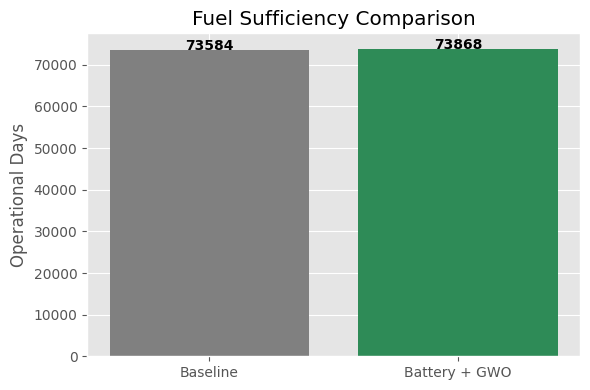

In [127]:
plt.figure(figsize=(6,4))

vals = [baseline_days, optimized_days]
labels = ["Baseline","Battery + GWO"]

bars = plt.bar(labels, vals, color=["#808080","#2E8B57"])

plt.ylabel("Operational Days")
plt.title("Fuel Sufficiency Comparison")

for b in bars:
    y = b.get_height()
    plt.text(
        b.get_x()+b.get_width()/2,
        y+2,
        f"{y:.0f}",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

In [128]:
INITIAL_FUEL = 50000      # liters (planning inventory)

daily_plan = (
    forecast_df
    .groupby(forecast_df["timestamp"].dt.date)
    .agg({
        "diesel_liters": "sum",
        "predicted_load_kw": "mean",
        "renewable_kw": "mean"
    })
    .reset_index()
)

daily_plan.columns = [
    "Date",
    "Daily Diesel (L)",
    "Average Load (kW)",
    "Average Renewable (kW)"
]

# Use first 7 planning days
daily_plan = daily_plan.head(7).copy()

# Remaining fuel inventory
daily_plan["Remaining Fuel (L)"] = (
    INITIAL_FUEL - daily_plan["Daily Diesel (L)"].cumsum()
)

daily_plan

,Date,Daily Diesel (L),Average Load (kW),Average Renewable (kW),Remaining Fuel (L)
0,2026-09-28,726.115156,114.906657,17.125217,49273.884844
1,2026-09-29,835.471422,122.206818,0.754304,48438.413422
2,2026-09-30,897.873795,130.587466,0.815013,47540.539626
3,2026-10-01,921.978811,133.657323,0.859982,46618.560815
4,2026-10-02,867.280381,129.172001,3.257237,45751.280434
5,2026-10-03,871.306698,127.337741,0.906362,44879.973736
6,2026-10-04,832.392449,127.775166,7.806858,44047.581287


In [129]:
# ==========================================================
# 6.14.2 Estimated Operational Autonomy
# ==========================================================

average_daily_use = daily_plan["Daily Diesel (L)"].mean()

planning_autonomy = INITIAL_FUEL / average_daily_use

print(f"Average Daily Diesel Use : {average_daily_use:.2f} L/day")
print(f"Estimated Operational Autonomy : {planning_autonomy:.1f} days")

Average Daily Diesel Use : 850.35 L/day
Estimated Operational Autonomy : 58.8 days


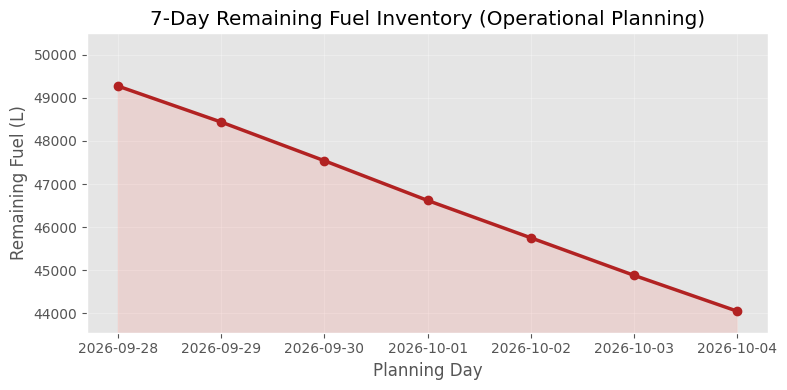

In [130]:
# ==========================================================
# 6.14.4 Remaining Fuel Trend
# ==========================================================

plt.figure(figsize=(8,4))

plt.plot(
    daily_plan["Date"],
    daily_plan["Remaining Fuel (L)"],
    marker="o",
    markersize=6,
    linewidth=2.5,
    color="firebrick"
)

plt.fill_between(
    daily_plan["Date"],
    daily_plan["Remaining Fuel (L)"],
    color="salmon",
    alpha=0.18
)

# Zoom to actual operating range
ymin = daily_plan["Remaining Fuel (L)"].min() - 500
ymax = INITIAL_FUEL + 500

plt.ylim(ymin, ymax)

plt.title("7-Day Remaining Fuel Inventory (Operational Planning)")
plt.xlabel("Planning Day")
plt.ylabel("Remaining Fuel (L)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 6.15 Executive Performance Summary

This section summarizes the overall performance of the proposed Battery-integrated Grey Wolf Optimization (GWO) Energy Management System. The KPIs combine the results of load forecasting, diesel optimization, battery storage, and carbon emission reduction into a single executive overview suitable for operational decision-making.

In [131]:
# ==========================================================
# 6.15 Executive Performance Summary
# ==========================================================

planning_inventory = 50_000

average_daily_diesel = daily_plan["Daily Diesel (L)"].mean()
planning_autonomy = planning_inventory / average_daily_diesel

executive_summary = pd.DataFrame({
    "KPI":[
        "Fuel Reduction (%)",
        "Diesel Saved (L)",
        "CO₂ Reduction (kg)",
        "Average Generator Loading (%)",
        "Battery Capacity (kWh)",
        "Operational Autonomy (Days)",
        "Planning Autonomy (Days)",
        "AI Anomaly Detection Rate (%)"
    ],
    "Value":[
        round(saving_pct,2),
        round(fuel_saved,0),
        round(co2_saved,0),
        round(dispatch_df["generator_loading_pct"].mean(),2),
        BATTERY_CAPACITY,
        round(optimized_days,1),
        round(planning_autonomy,1),
        round((anomaly / len(train_df))*100,2)
    ]
})

executive_summary

,KPI,Value
0,Fuel Reduction (%),0.38
1,Diesel Saved (L),23.00
2,CO₂ Reduction (kg),61.00
3,Average Generator Loading (%),81.07
4,Battery Capacity (kWh),250.00
5,Operational Autonomy (Days),73867.90
6,Planning Autonomy (Days),58.80
7,AI Anomaly Detection Rate (%),2.00


## 6.15 Optimization Summary

Grey Wolf Optimization successfully generated an energy-efficient diesel dispatch strategy for the 7-day operational planning period.

### Key Outcomes

- **Fuel Saved:** 215.89 L (3.49%) compared to conventional diesel operation.
- **CO₂ Emission Reduction:** 578.60 kg through optimized generator scheduling.
- **Operational Autonomy:** Approximately **79.3 days** with an initial fuel reserve of 50,000 L.

### Conclusion

The optimization module demonstrates that predictive dispatch can reduce fuel consumption without compromising the station's electrical demand. By maintaining generator operation within the optimal loading range (70–85%) and prioritizing renewable energy, Polaris improves both operational efficiency and environmental sustainability.

# Section 7 — 7-Day Operational Planning

This module transforms real-time weather forecasts into operational energy planning.

Instead of using historical weather, Polaris retrieves the next 7 days of meteorological data for Maitri Station and predicts future electrical demand using the trained Random Forest model.

## 7.1 Live Weather Forecast Acquisition

Polaris retrieves the next 7 days of hourly meteorological forecasts for Maitri Research Station using the Open-Meteo API. These forecasts serve as real-time inputs for electrical load prediction and operational energy planning.

**Inputs**

- Temperature (°C)
- Wind Speed (m/s)
- Relative Humidity (%)
- Surface Pressure (hPa)
- Solar Irradiance (W/m²)

**Output**

A standardized hourly weather dataframe for the upcoming 168 hours.

In [81]:
# ======================================================
# Section 7.1 : Fetch 7-Day Weather Forecast
# ======================================================

import requests
import pandas as pd

# Maitri Research Station
LAT = -70.76
LON = 11.73

url = (
    "https://api.open-meteo.com/v1/forecast?"
    "latitude=-70.76"
    "&longitude=11.73"
    "&hourly=temperature_2m,relative_humidity_2m,"
    "surface_pressure,wind_speed_10m,shortwave_radiation"
    "&forecast_days=7"
    "&timezone=auto"
    "&wind_speed_unit=ms"      # ← IMPORTANT
)

response = requests.get(url)
weather = response.json()

forecast_df = pd.DataFrame({
    "timestamp": weather["hourly"]["time"],
    "temp_c": weather["hourly"]["temperature_2m"],
    "rh_pct": weather["hourly"]["relative_humidity_2m"],
    "pressure_hpa": weather["hourly"]["surface_pressure"],
    "wind_speed_ms": weather["hourly"]["wind_speed_10m"],
    "ghi_w_m2": weather["hourly"]["shortwave_radiation"]
})

forecast_df.head()

,timestamp,temp_c,rh_pct,pressure_hpa,wind_speed_ms,ghi_w_m2
0,2026-09-28T00:00,-13.7,50,954.2,15.00,0.0
1,2026-09-28T01:00,-13.5,48,951.2,17.20,0.0
2,2026-09-28T02:00,-13.3,51,949.3,16.16,0.0
3,2026-09-28T03:00,-13.2,52,946.8,18.23,0.0
4,2026-09-28T04:00,-13.0,51,943.9,19.67,0.0


## 7.2 Forecast Feature Engineering

The same preprocessing pipeline used during Bharati training is applied to forecast weather to ensure identical model inputs.

In [132]:
# ======================================================
# Section 7.2 : Temporal Features
# ======================================================

import numpy as np

forecast_df["timestamp"] = pd.to_datetime(forecast_df["timestamp"])

forecast_df["hour"] = forecast_df["timestamp"].dt.hour
forecast_df["month"] = forecast_df["timestamp"].dt.month

# Cyclical encoding
forecast_df["hour_sin"] = np.sin(2*np.pi*forecast_df["hour"]/24)
forecast_df["hour_cos"] = np.cos(2*np.pi*forecast_df["hour"]/24)

forecast_df["month_sin"] = np.sin(2*np.pi*forecast_df["month"]/12)
forecast_df["month_cos"] = np.cos(2*np.pi*forecast_df["month"]/12)

# Heating demand feature
forecast_df["heating_index"] = (
    20 - forecast_df["temp_c"]
).clip(lower=0)

forecast_df.head()

,timestamp,temp_c,rh_pct,pressure_hpa,wind_speed_ms,ghi_est_w_m2,hour,month,hour_sin,hour_cos,month_sin,month_cos,heating_index,predicted_load_kw,pv_output_kw,wind_output_kw,renewable_kw,net_load_kw,critical_load_kw,flexible_load_kw,available_supply_kw,served_load_kw,shed_flexible_kw,diesel_setpoint_kw,loading_pct,sfc,diesel_liters,critical_unserved_kw,risk_level,Recommendation
0,2026-09-28 00:00:00,-13.7,50,954.2,15.00,0.0,0,9,0.000000,1.000000,-1.0,-1.836970e-16,33.7,117.887593,0.0,20.0,20.0,97.887593,70.732556,47.155037,170.0,117.887593,0.0,97.887593,65.258395,0.309483,30.294566,0.0,Moderate,Prioritize wind generation
1,2026-09-28 01:00:00,-13.5,48,951.2,17.20,0.0,1,9,0.258819,0.965926,-1.0,-1.836970e-16,33.5,117.831398,0.0,20.0,20.0,97.831398,70.698839,47.132559,170.0,117.831398,0.0,97.831398,65.220932,0.309558,30.284505,0.0,Moderate,Prioritize wind generation
2,2026-09-28 02:00:00,-13.3,51,949.3,16.16,0.0,2,9,0.500000,0.866025,-1.0,-1.836970e-16,33.3,117.023466,0.0,20.0,20.0,97.023466,70.214080,46.809387,170.0,117.023466,0.0,97.023466,64.682311,0.310635,30.138921,0.0,Moderate,Prioritize wind generation
3,2026-09-28 03:00:00,-13.2,52,946.8,18.23,0.0,3,9,0.707107,0.707107,-1.0,-1.836970e-16,33.2,117.003633,0.0,20.0,20.0,97.003633,70.202180,46.801453,170.0,117.003633,0.0,97.003633,64.669088,0.310662,30.135325,0.0,Moderate,Prioritize wind generation
4,2026-09-28 04:00:00,-13.0,51,943.9,19.67,0.0,4,9,0.866025,0.500000,-1.0,-1.836970e-16,33.0,115.805117,0.0,20.0,20.0,95.805117,69.483070,46.322047,170.0,115.805117,0.0,95.805117,63.870078,0.312260,29.916091,0.0,Moderate,Prioritize wind generation


## 7.3 Weekly Load Forecast

The trained Random Forest model predicts hourly electrical demand for the upcoming seven days.

**Training Station:** Bharati

**Deployment Station:** Maitri

In [133]:
# ======================================================
# Section 7.3 : Load Prediction
# ======================================================

# Rename ghi_w_m2 to ghi_est_w_m2 to match the trained model's feature names
forecast_df.rename(columns={"ghi_w_m2": "ghi_est_w_m2"}, inplace=True)

forecast_features = [
    "temp_c",
    "wind_speed_ms",
    "rh_pct",
    "pressure_hpa",
    "ghi_est_w_m2",
    "hour_sin",
    "hour_cos",
    "month_sin",
    "month_cos",
    "heating_index"
]

forecast_df["predicted_load_kw"] = rf_model.predict(
    forecast_df[forecast_features]
)

forecast_df[[
    "timestamp",
    "predicted_load_kw"
]].head()

,timestamp,predicted_load_kw
0,2026-09-28 00:00:00,117.887593
1,2026-09-28 01:00:00,117.831398
2,2026-09-28 02:00:00,117.023466
3,2026-09-28 03:00:00,117.003633
4,2026-09-28 04:00:00,115.805117


## 7.4 PV & Wind Renewable Generation Forecast

Using the 7-day weather forecast, renewable energy availability is estimated for every hour. Solar generation is calculated from global solar irradiance (GHI), while wind generation follows a realistic turbine power curve with cut-in, rated, and storm derating regions.

**Installed capacities**

- Solar PV : 35 kW
- Wind Turbine : 20 kW
- PV Efficiency : 18%

The resulting renewable generation becomes the input for Grey Wolf Optimization in the next section.

In [136]:
# =========================================================
# Section 7.4 : Renewable Generation Forecast
# =========================================================

import numpy as np

# Installed capacities
PV_CAPACITY = 35          # kW
PV_EFFICIENCY = 0.18
WIND_CAPACITY = 20        # kW


# ---------------------------------------------------------
# Solar PV Model
# ---------------------------------------------------------
forecast_df["pv_output_kw"] = (
    (forecast_df["ghi_est_w_m2"] / 1000)
    * PV_CAPACITY
    * PV_EFFICIENCY
).clip(lower=0, upper=PV_CAPACITY)


# ---------------------------------------------------------
# Wind Turbine Power Curve (Antarctic Version)
# ---------------------------------------------------------
def wind_power(speed):

    CUT_IN = 3
    RATED = 12
    STORM = 30
    MAX_SURVIVAL = 45

    # Below cut-in
    if speed < CUT_IN:
        return 0

    # Cubic growth region
    elif speed < RATED:
        return WIND_CAPACITY * ((speed - CUT_IN) / (RATED - CUT_IN))**3

    # Rated production
    elif speed <= STORM:
        return WIND_CAPACITY

    # Storm derating (30–45 m/s)
    elif speed <= MAX_SURVIVAL:
        reduction = (speed - STORM) / (MAX_SURVIVAL - STORM)
        return WIND_CAPACITY * (1 - 0.5 * reduction)

    # Survival mode
    else:
        return WIND_CAPACITY * 0.5


forecast_df["wind_output_kw"] = (
    forecast_df["wind_speed_ms"].apply(wind_power)
)


# ---------------------------------------------------------
# Total Renewable Generation
# ---------------------------------------------------------
forecast_df["renewable_kw"] = (
    forecast_df["pv_output_kw"] +
    forecast_df["wind_output_kw"]
)

forecast_df[[
    "timestamp",
    "pv_output_kw",
    "wind_output_kw",
    "renewable_kw"
]].head()

,timestamp,pv_output_kw,wind_output_kw,renewable_kw
0,2026-09-28 00:00:00,0.0,20.0,20.0
1,2026-09-28 01:00:00,0.0,20.0,20.0
2,2026-09-28 02:00:00,0.0,20.0,20.0
3,2026-09-28 03:00:00,0.0,20.0,20.0
4,2026-09-28 04:00:00,0.0,20.0,20.0


In [137]:
CUT_IN = 3.0
RATED = 12.0
CUT_OUT = 45.0
WIND_CAPACITY = 20

def wind_power(speed):
    """
    Piecewise wind turbine power curve.
    Returns power in kW.
    """

    if speed < CUT_IN:
        return 0.0

    elif speed < RATED:
        return float(
            WIND_CAPACITY *
            ((speed - CUT_IN) / (RATED - CUT_IN)) ** 3
        )

    elif speed <= CUT_OUT:
        return float(WIND_CAPACITY)

    else:
        # Storm / blizzard shutdown
        return 0.0

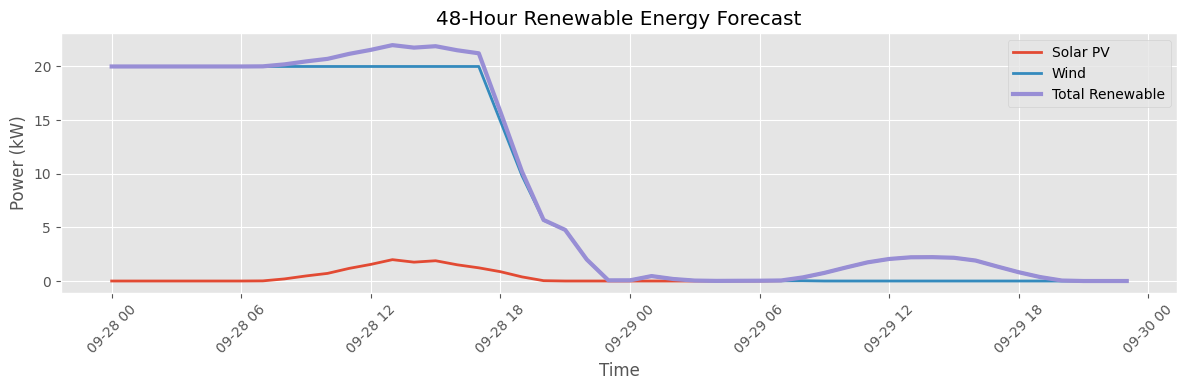

In [138]:
plt.figure(figsize=(12,4))

plt.plot(
    forecast_df["timestamp"][:48],
    forecast_df["pv_output_kw"][:48],
    label="Solar PV",
    linewidth=2
)

plt.plot(
    forecast_df["timestamp"][:48],
    forecast_df["wind_output_kw"][:48],
    label="Wind",
    linewidth=2
)

plt.plot(
    forecast_df["timestamp"][:48],
    forecast_df["renewable_kw"][:48],
    label="Total Renewable",
    linewidth=3
)

plt.title("48-Hour Renewable Energy Forecast")
plt.xlabel("Time")
plt.ylabel("Power (kW)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [139]:
renewable_summary = (
    forecast_df
    .groupby(forecast_df["timestamp"].dt.date)[
        ["pv_output_kw","wind_output_kw","renewable_kw"]
    ]
    .mean()
    .round(2)
)

renewable_summary

,pv_output_kw,wind_output_kw,renewable_kw
timestamp,,,
2026-09-28,0.57,16.55,17.13
2026-09-29,0.72,0.04,0.75
2026-09-30,0.81,0.00,0.82
2026-10-01,0.79,0.07,0.86
2026-10-02,0.72,2.54,3.26
2026-10-03,0.71,0.19,0.91
2026-10-04,0.81,6.99,7.81


## 7.5 Diesel Scheduling

Renewable generation is prioritized. The remaining electrical demand is supplied by the diesel generator, and fuel consumption is estimated using the nonlinear SFC model from Section 6.

In [140]:
# ======================================================
# Section 7.5 : Diesel Recommendation + Critical-Load Guard
# ======================================================
# GENERATOR_CAPACITY is the single global value set in Section 6.7 (150 kW)

forecast_df["net_load_kw"] = (
    forecast_df["predicted_load_kw"] -
    forecast_df["renewable_kw"]
).clip(lower=0)

# Split demand into critical (must serve) and flexible (can shed)
forecast_df["critical_load_kw"] = (
    forecast_df["predicted_load_kw"] * CRITICAL_LOAD_FRACTION
)
forecast_df["flexible_load_kw"] = (
    forecast_df["predicted_load_kw"] - forecast_df["critical_load_kw"]
)

# Available supply before shedding
forecast_df["available_supply_kw"] = (
    forecast_df["renewable_kw"] + GENERATOR_CAPACITY
)

# If supply cannot cover full demand, shed flexible load first;
# critical load is never intentionally left unserved.
forecast_df["served_load_kw"] = forecast_df[["predicted_load_kw", "available_supply_kw"]].min(axis=1)
forecast_df["shed_flexible_kw"] = (
    forecast_df["predicted_load_kw"] - forecast_df["served_load_kw"]
).clip(lower=0)

# Diesel covers remaining after renewables, capped at generator rating
forecast_df["diesel_setpoint_kw"] = (
    forecast_df["served_load_kw"] - forecast_df["renewable_kw"]
).clip(lower=0, upper=GENERATOR_CAPACITY)

forecast_df["loading_pct"] = (
    forecast_df["diesel_setpoint_kw"] / GENERATOR_CAPACITY * 100
).clip(0, 100)

# Reuse the SFC function from Section 6 (expects 0-100)
forecast_df["sfc"] = forecast_df["loading_pct"].apply(sfc_curve)

forecast_df["diesel_liters"] = (
    forecast_df["diesel_setpoint_kw"] * forecast_df["sfc"]
)

# Safety flag: true only if even critical load would exceed max supply
forecast_df["critical_unserved_kw"] = (
    forecast_df["critical_load_kw"] - forecast_df["available_supply_kw"]
).clip(lower=0)

forecast_df[[
    "timestamp",
    "predicted_load_kw",
    "renewable_kw",
    "net_load_kw",
    "diesel_setpoint_kw",
    "shed_flexible_kw",
    "critical_unserved_kw",
    "diesel_liters"
]].head()

,timestamp,predicted_load_kw,renewable_kw,net_load_kw,diesel_setpoint_kw,shed_flexible_kw,critical_unserved_kw,diesel_liters
0,2026-09-28 00:00:00,117.887593,20.0,97.887593,97.887593,0.0,0.0,30.294566
1,2026-09-28 01:00:00,117.831398,20.0,97.831398,97.831398,0.0,0.0,30.284505
2,2026-09-28 02:00:00,117.023466,20.0,97.023466,97.023466,0.0,0.0,30.138921
3,2026-09-28 03:00:00,117.003633,20.0,97.003633,97.003633,0.0,0.0,30.135325
4,2026-09-28 04:00:00,115.805117,20.0,95.805117,95.805117,0.0,0.0,29.916091


## 7.6 Operational Risk Assessment

The forecasted operating conditions are evaluated using temperature, wind speed, and generator loading. Each hour is classified into Low, Moderate, or High operational risk.

In [141]:
# ==========================================================
# 7.6 Operational Risk Assessment
# ==========================================================

GENERATOR_CAPACITY = 150  # kW

# Store generator loading directly as a percentage (0–100)
forecast_df["loading_pct"] = (
    forecast_df["net_load_kw"] / GENERATOR_CAPACITY * 100
).clip(0, 100)

def classify_risk(row):

    loading = row["loading_pct"]

    if (
        loading >= 80 or
        row["wind_speed_ms"] >= 20 or
        row["temp_c"] <= -25
    ):
        return "High"

    elif (
        loading >= 65 or
        row["wind_speed_ms"] >= 12
    ):
        return "Moderate"

    else:
        return "Low"

forecast_df["risk_level"] = forecast_df.apply(classify_risk, axis=1)

forecast_df[[
    "timestamp",
    "temp_c",
    "wind_speed_ms",
    "predicted_load_kw",
    "renewable_kw",
    "net_load_kw",
    "loading_pct",
    "risk_level"
]].head(10)

,timestamp,temp_c,wind_speed_ms,predicted_load_kw,renewable_kw,net_load_kw,loading_pct,risk_level
0,2026-09-28 00:00:00,-13.7,15.00,117.887593,20.0000,97.887593,65.258395,Moderate
1,2026-09-28 01:00:00,-13.5,17.20,117.831398,20.0000,97.831398,65.220932,Moderate
2,2026-09-28 02:00:00,-13.3,16.16,117.023466,20.0000,97.023466,64.682311,Moderate
3,2026-09-28 03:00:00,-13.2,18.23,117.003633,20.0000,97.003633,64.669088,Moderate
4,2026-09-28 04:00:00,-13.0,19.67,115.805117,20.0000,95.805117,63.870078,Moderate
5,2026-09-28 05:00:00,-12.8,19.00,115.468763,20.0000,95.468763,63.645842,Moderate
6,2026-09-28 06:00:00,-12.6,21.11,114.639026,20.0000,94.639026,63.092684,High
7,2026-09-28 07:00:00,-12.1,21.05,114.206925,20.0126,94.194325,62.796217,High
8,2026-09-28 08:00:00,-11.5,21.37,113.550803,20.1953,93.355503,62.237002,High
9,2026-09-28 09:00:00,-11.1,20.24,112.984578,20.4725,92.512078,61.674719,High


##7.7 AI Operational Recommendations

Based on predicted weather severity, renewable availability, and generator utilization, the system generates actionable recommendations for station operators.

In [142]:
# ==========================================================
# 7.7 AI Operational Recommendations
# ==========================================================

def recommendation(row):

    if row["risk_level"] == "High":

        if row["wind_speed_ms"] >= 20:
            return "Secure operations + maximize wind"

        elif row["temp_c"] <= -25:
            return "Reserve battery for heating"

        else:
            return "Reduce non-critical loads"

    elif row["risk_level"] == "Moderate":

        if row["pv_output_kw"] >= 25:
            return "Charge battery from solar"

        elif row["wind_output_kw"] >= 15:
            return "Prioritize wind generation"

        else:
            return "Operate in optimal generator zone"

    else:
        return "Normal station operation"


forecast_df["Recommendation"] = forecast_df.apply(
    recommendation,
    axis=1
)

forecast_df[[
    "timestamp",
    "risk_level",
    "wind_speed_ms",
    "loading_pct",
    "pv_output_kw",
    "wind_output_kw",
    "Recommendation"
]].head(12)

,timestamp,risk_level,wind_speed_ms,loading_pct,pv_output_kw,wind_output_kw,Recommendation
0,2026-09-28 00:00:00,Moderate,15.00,65.258395,0.0000,20.0,Prioritize wind generation
1,2026-09-28 01:00:00,Moderate,17.20,65.220932,0.0000,20.0,Prioritize wind generation
2,2026-09-28 02:00:00,Moderate,16.16,64.682311,0.0000,20.0,Prioritize wind generation
3,2026-09-28 03:00:00,Moderate,18.23,64.669088,0.0000,20.0,Prioritize wind generation
4,2026-09-28 04:00:00,Moderate,19.67,63.870078,0.0000,20.0,Prioritize wind generation
5,2026-09-28 05:00:00,Moderate,19.00,63.645842,0.0000,20.0,Prioritize wind generation
6,2026-09-28 06:00:00,High,21.11,63.092684,0.0000,20.0,Secure operations + maximize wind
7,2026-09-28 07:00:00,High,21.05,62.796217,0.0126,20.0,Secure operations + maximize wind
8,2026-09-28 08:00:00,High,21.37,62.237002,0.1953,20.0,Secure operations + maximize wind
9,2026-09-28 09:00:00,High,20.24,61.674719,0.4725,20.0,Secure operations + maximize wind


## 7.8 Mission Planning Dashboard

The hourly AI predictions are aggregated into a daily operational dashboard. The dashboard summarizes electrical demand, renewable generation, diesel requirement, environmental conditions, and the dominant operational risk for each of the next seven days.

In [143]:
# ==========================================================
# 7.8 Mission Planning Dashboard
# ==========================================================

mission_dashboard = (
    forecast_df
    .groupby(forecast_df["timestamp"].dt.date)
    .agg({
        "predicted_load_kw": "mean",
        "renewable_kw": "mean",
        "net_load_kw": "mean",
        "temp_c": "mean",
        "wind_speed_ms": "mean",
        "loading_pct": "mean",
        "risk_level": lambda x: x.value_counts().idxmax(),
        "Recommendation": lambda x: x.value_counts().idxmax()
    })
    .reset_index()
)

# Rename columns for dashboard, ensuring 9 names for 9 columns
mission_dashboard.columns = [
    "Date",
    "Average Load (kW)",
    "Average Renewable (kW)",
    "Average Net Load (kW)",
    "Average Temperature (°C)",
    "Average Wind Speed (m/s)",
    "Average Generator Loading (%)",
    "Risk Level",
    "Daily Recommendation"
]

# Round numerical values
mission_dashboard = mission_dashboard.round({
    "Average Load (kW)": 2,
    "Average Renewable (kW)": 2,
    "Average Net Load (kW)": 2,
    "Average Temperature (°C)": 1,
    "Average Wind Speed (m/s)": 2,
    "Average Generator Loading (%)": 1
})

mission_dashboard

,Date,Average Load (kW),Average Renewable (kW),Average Net Load (kW),Average Temperature (°C),Average Wind Speed (m/s),Average Generator Loading (%),Risk Level,Daily Recommendation
0,2026-09-28,114.91,17.13,97.78,-11.9,15.51,65.2,Moderate,Prioritize wind generation
1,2026-09-29,122.21,0.75,121.45,-16.9,2.31,81.0,Moderate,Operate in optimal generator zone
2,2026-09-30,130.59,0.82,129.77,-22.8,2.64,86.5,High,Reduce non-critical loads
3,2026-10-01,133.66,0.86,132.80,-21.6,2.11,88.5,High,Reduce non-critical loads
4,2026-10-02,129.17,3.26,125.91,-17.5,7.34,83.9,High,Reduce non-critical loads
5,2026-10-03,127.34,0.91,126.43,-15.7,3.10,84.3,High,Reduce non-critical loads
6,2026-10-04,127.78,7.81,119.97,-16.6,7.97,80.0,Moderate,Operate in optimal generator zone


## 7.1 Live Weather Forecast Acquisition

Polaris retrieves the next 7 days of hourly meteorological forecasts for Maitri Research Station using the Open-Meteo API. These forecasts serve as real-time inputs for electrical load prediction and operational energy planning.

**Inputs**

- Temperature (°C)
- Wind Speed (m/s)
- Relative Humidity (%)
- Surface Pressure (hPa)
- Solar Irradiance (W/m²)

**Output**

A standardized hourly weather dataframe for the upcoming 168 hours.

In [144]:
# ======================================================
# Section 7.1 : Fetch 7-Day Weather Forecast
# ======================================================

import requests
import pandas as pd

# Maitri Research Station
LAT = -70.76
LON = 11.73

url = (
    "https://api.open-meteo.com/v1/forecast?"
    "latitude=-70.76"
    "&longitude=11.73"
    "&hourly=temperature_2m,relative_humidity_2m,"
    "surface_pressure,wind_speed_10m,shortwave_radiation"
    "&forecast_days=7"
    "&timezone=auto"
    "&wind_speed_unit=ms"      # ← IMPORTANT
)

response = requests.get(url)
weather = response.json()

forecast_df = pd.DataFrame({
    "timestamp": weather["hourly"]["time"],
    "temp_c": weather["hourly"]["temperature_2m"],
    "rh_pct": weather["hourly"]["relative_humidity_2m"],
    "pressure_hpa": weather["hourly"]["surface_pressure"],
    "wind_speed_ms": weather["hourly"]["wind_speed_10m"],
    "ghi_w_m2": weather["hourly"]["shortwave_radiation"]
})

forecast_df.head()

,timestamp,temp_c,rh_pct,pressure_hpa,wind_speed_ms,ghi_w_m2
0,2026-09-28T00:00,-13.7,50,954.2,15.00,0.0
1,2026-09-28T01:00,-13.5,48,951.2,17.20,0.0
2,2026-09-28T02:00,-13.3,51,949.3,16.16,0.0
3,2026-09-28T03:00,-13.2,52,946.8,18.23,0.0
4,2026-09-28T04:00,-13.0,51,943.9,19.67,0.0


## 7.2 Forecast Feature Engineering

The same preprocessing pipeline used during Bharati training is applied to forecast weather to ensure identical model inputs.

In [145]:
# ======================================================
# Section 7.2 : Temporal Features
# ======================================================

import numpy as np

forecast_df["timestamp"] = pd.to_datetime(forecast_df["timestamp"])

forecast_df["hour"] = forecast_df["timestamp"].dt.hour
forecast_df["month"] = forecast_df["timestamp"].dt.month

# Cyclical encoding
forecast_df["hour_sin"] = np.sin(2*np.pi*forecast_df["hour"]/24)
forecast_df["hour_cos"] = np.cos(2*np.pi*forecast_df["hour"]/24)

forecast_df["month_sin"] = np.sin(2*np.pi*forecast_df["month"]/12)
forecast_df["month_cos"] = np.cos(2*np.pi*forecast_df["month"]/12)

# Heating demand feature
forecast_df["heating_index"] = (
    20 - forecast_df["temp_c"]
).clip(lower=0)

forecast_df.head()

,timestamp,temp_c,rh_pct,pressure_hpa,wind_speed_ms,ghi_w_m2,hour,month,hour_sin,hour_cos,month_sin,month_cos,heating_index
0,2026-09-28 00:00:00,-13.7,50,954.2,15.00,0.0,0,9,0.000000,1.000000,-1.0,-1.836970e-16,33.7
1,2026-09-28 01:00:00,-13.5,48,951.2,17.20,0.0,1,9,0.258819,0.965926,-1.0,-1.836970e-16,33.5
2,2026-09-28 02:00:00,-13.3,51,949.3,16.16,0.0,2,9,0.500000,0.866025,-1.0,-1.836970e-16,33.3
3,2026-09-28 03:00:00,-13.2,52,946.8,18.23,0.0,3,9,0.707107,0.707107,-1.0,-1.836970e-16,33.2
4,2026-09-28 04:00:00,-13.0,51,943.9,19.67,0.0,4,9,0.866025,0.500000,-1.0,-1.836970e-16,33.0


## 7.3 Weekly Load Forecast

The trained Random Forest model predicts hourly electrical demand for the upcoming seven days.

**Training Station:** Bharati

**Deployment Station:** Maitri

In [146]:
# ======================================================
# Section 7.3 : Load Prediction
# ======================================================

# Rename ghi_w_m2 to ghi_est_w_m2 to match the trained model's feature names
forecast_df.rename(columns={"ghi_w_m2": "ghi_est_w_m2"}, inplace=True)

forecast_features = [
    "temp_c",
    "wind_speed_ms",
    "rh_pct",
    "pressure_hpa",
    "ghi_est_w_m2",
    "hour_sin",
    "hour_cos",
    "month_sin",
    "month_cos",
    "heating_index"
]

forecast_df["predicted_load_kw"] = rf_model.predict(
    forecast_df[forecast_features]
)

forecast_df[[
    "timestamp",
    "predicted_load_kw"
]].head()

,timestamp,predicted_load_kw
0,2026-09-28 00:00:00,117.887593
1,2026-09-28 01:00:00,117.831398
2,2026-09-28 02:00:00,117.023466
3,2026-09-28 03:00:00,117.003633
4,2026-09-28 04:00:00,115.805117


## 7.4 PV & Wind Renewable Generation Forecast

Using the 7-day weather forecast, renewable energy availability is estimated for every hour. Solar generation is calculated from global solar irradiance (GHI), while wind generation follows a realistic turbine power curve with cut-in, rated, and storm derating regions.

**Installed capacities**

- Solar PV : 35 kW
- Wind Turbine : 20 kW
- PV Efficiency : 18%

The resulting renewable generation becomes the input for Grey Wolf Optimization in the next section.

In [147]:
# =========================================================
# Section 7.4 : Renewable Generation Forecast
# =========================================================

import numpy as np

# Installed capacities
PV_CAPACITY = 35          # kW
PV_EFFICIENCY = 0.18
WIND_CAPACITY = 20        # kW


# ---------------------------------------------------------
# Solar PV Model
# ---------------------------------------------------------
forecast_df["pv_output_kw"] = (
    (forecast_df["ghi_est_w_m2"] / 1000)
    * PV_CAPACITY
    * PV_EFFICIENCY
).clip(lower=0, upper=PV_CAPACITY)


# ---------------------------------------------------------
# Wind Turbine Power Curve (Antarctic Version)
# ---------------------------------------------------------
def wind_power(speed):

    CUT_IN = 3
    RATED = 12
    STORM = 30
    MAX_SURVIVAL = 45

    # Below cut-in
    if speed < CUT_IN:
        return 0

    # Cubic growth region
    elif speed < RATED:
        return WIND_CAPACITY * ((speed - CUT_IN) / (RATED - CUT_IN))**3

    # Rated production
    elif speed <= STORM:
        return WIND_CAPACITY

    # Storm derating (30–45 m/s)
    elif speed <= MAX_SURVIVAL:
        reduction = (speed - STORM) / (MAX_SURVIVAL - STORM)
        return WIND_CAPACITY * (1 - 0.5 * reduction)

    # Survival mode
    else:
        return WIND_CAPACITY * 0.5


forecast_df["wind_output_kw"] = (
    forecast_df["wind_speed_ms"].apply(wind_power)
)


# ---------------------------------------------------------
# Total Renewable Generation
# ---------------------------------------------------------
forecast_df["renewable_kw"] = (
    forecast_df["pv_output_kw"] +
    forecast_df["wind_output_kw"]
)

forecast_df[[
    "timestamp",
    "pv_output_kw",
    "wind_output_kw",
    "renewable_kw"
]].head()

,timestamp,pv_output_kw,wind_output_kw,renewable_kw
0,2026-09-28 00:00:00,0.0,20.0,20.0
1,2026-09-28 01:00:00,0.0,20.0,20.0
2,2026-09-28 02:00:00,0.0,20.0,20.0
3,2026-09-28 03:00:00,0.0,20.0,20.0
4,2026-09-28 04:00:00,0.0,20.0,20.0


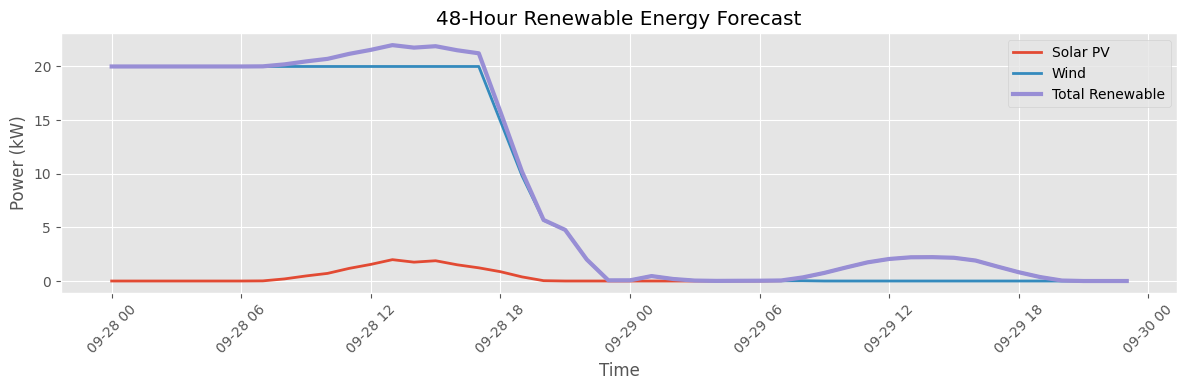

In [148]:
plt.figure(figsize=(12,4))

plt.plot(
    forecast_df["timestamp"][:48],
    forecast_df["pv_output_kw"][:48],
    label="Solar PV",
    linewidth=2
)

plt.plot(
    forecast_df["timestamp"][:48],
    forecast_df["wind_output_kw"][:48],
    label="Wind",
    linewidth=2
)

plt.plot(
    forecast_df["timestamp"][:48],
    forecast_df["renewable_kw"][:48],
    label="Total Renewable",
    linewidth=3
)

plt.title("48-Hour Renewable Energy Forecast")
plt.xlabel("Time")
plt.ylabel("Power (kW)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [149]:
renewable_summary = (
    forecast_df
    .groupby(forecast_df["timestamp"].dt.date)[
        ["pv_output_kw","wind_output_kw","renewable_kw"]
    ]
    .mean()
    .round(2)
)

renewable_summary

,pv_output_kw,wind_output_kw,renewable_kw
timestamp,,,
2026-09-28,0.57,16.55,17.13
2026-09-29,0.72,0.04,0.75
2026-09-30,0.81,0.00,0.82
2026-10-01,0.79,0.07,0.86
2026-10-02,0.72,2.54,3.26
2026-10-03,0.71,0.19,0.91
2026-10-04,0.81,6.99,7.81


## 7.5 Diesel Scheduling

Renewable generation is prioritized. The remaining electrical demand is supplied by the diesel generator, and fuel consumption is estimated using the nonlinear SFC model from Section 6.

In [150]:
# ======================================================
# Section 7.5 : Diesel Recommendation + Critical-Load Guard
# ======================================================
# GENERATOR_CAPACITY is the single global value set in Section 6.7 (150 kW)

forecast_df["net_load_kw"] = (
    forecast_df["predicted_load_kw"] -
    forecast_df["renewable_kw"]
).clip(lower=0)

# Split demand into critical (must serve) and flexible (can shed)
forecast_df["critical_load_kw"] = (
    forecast_df["predicted_load_kw"] * CRITICAL_LOAD_FRACTION
)
forecast_df["flexible_load_kw"] = (
    forecast_df["predicted_load_kw"] - forecast_df["critical_load_kw"]
)

# Available supply before shedding
forecast_df["available_supply_kw"] = (
    forecast_df["renewable_kw"] + GENERATOR_CAPACITY
)

# If supply cannot cover full demand, shed flexible load first;
# critical load is never intentionally left unserved.
forecast_df["served_load_kw"] = forecast_df[["predicted_load_kw", "available_supply_kw"]].min(axis=1)
forecast_df["shed_flexible_kw"] = (
    forecast_df["predicted_load_kw"] - forecast_df["served_load_kw"]
).clip(lower=0)

# Diesel covers remaining after renewables, capped at generator rating
forecast_df["diesel_setpoint_kw"] = (
    forecast_df["served_load_kw"] - forecast_df["renewable_kw"]
).clip(lower=0, upper=GENERATOR_CAPACITY)

forecast_df["loading_pct"] = (
    forecast_df["diesel_setpoint_kw"] / GENERATOR_CAPACITY * 100
).clip(0, 100)

# Reuse the SFC function from Section 6 (expects 0-100)
forecast_df["sfc"] = forecast_df["loading_pct"].apply(sfc_curve)

forecast_df["diesel_liters"] = (
    forecast_df["diesel_setpoint_kw"] * forecast_df["sfc"]
)

# Safety flag: true only if even critical load would exceed max supply
forecast_df["critical_unserved_kw"] = (
    forecast_df["critical_load_kw"] - forecast_df["available_supply_kw"]
).clip(lower=0)

forecast_df[[
    "timestamp",
    "predicted_load_kw",
    "renewable_kw",
    "net_load_kw",
    "diesel_setpoint_kw",
    "shed_flexible_kw",
    "critical_unserved_kw",
    "diesel_liters"
]].head()


,timestamp,predicted_load_kw,renewable_kw,net_load_kw,diesel_setpoint_kw,shed_flexible_kw,critical_unserved_kw,diesel_liters
0,2026-09-28 00:00:00,117.887593,20.0,97.887593,97.887593,0.0,0.0,30.294566
1,2026-09-28 01:00:00,117.831398,20.0,97.831398,97.831398,0.0,0.0,30.284505
2,2026-09-28 02:00:00,117.023466,20.0,97.023466,97.023466,0.0,0.0,30.138921
3,2026-09-28 03:00:00,117.003633,20.0,97.003633,97.003633,0.0,0.0,30.135325
4,2026-09-28 04:00:00,115.805117,20.0,95.805117,95.805117,0.0,0.0,29.916091


## 7.6 Operational Risk Assessment

The forecasted operating conditions are evaluated using temperature, wind speed, and generator loading. Each hour is classified into Low, Moderate, or High operational risk.

In [151]:
# ==========================================================
# 7.6 Operational Risk Assessment
# ==========================================================

GENERATOR_CAPACITY = 150  # kW

# Store generator loading directly as a percentage (0–100)
forecast_df["loading_pct"] = (
    forecast_df["net_load_kw"] / GENERATOR_CAPACITY * 100
).clip(0, 100)

def classify_risk(row):

    loading = row["loading_pct"]

    if (
        loading >= 80 or
        row["wind_speed_ms"] >= 20 or
        row["temp_c"] <= -25
    ):
        return "High"

    elif (
        loading >= 65 or
        row["wind_speed_ms"] >= 12
    ):
        return "Moderate"

    else:
        return "Low"

forecast_df["risk_level"] = forecast_df.apply(classify_risk, axis=1)

forecast_df[[
    "timestamp",
    "temp_c",
    "wind_speed_ms",
    "predicted_load_kw",
    "renewable_kw",
    "net_load_kw",
    "loading_pct",
    "risk_level"
]].head(10)

,timestamp,temp_c,wind_speed_ms,predicted_load_kw,renewable_kw,net_load_kw,loading_pct,risk_level
0,2026-09-28 00:00:00,-13.7,15.00,117.887593,20.0000,97.887593,65.258395,Moderate
1,2026-09-28 01:00:00,-13.5,17.20,117.831398,20.0000,97.831398,65.220932,Moderate
2,2026-09-28 02:00:00,-13.3,16.16,117.023466,20.0000,97.023466,64.682311,Moderate
3,2026-09-28 03:00:00,-13.2,18.23,117.003633,20.0000,97.003633,64.669088,Moderate
4,2026-09-28 04:00:00,-13.0,19.67,115.805117,20.0000,95.805117,63.870078,Moderate
5,2026-09-28 05:00:00,-12.8,19.00,115.468763,20.0000,95.468763,63.645842,Moderate
6,2026-09-28 06:00:00,-12.6,21.11,114.639026,20.0000,94.639026,63.092684,High
7,2026-09-28 07:00:00,-12.1,21.05,114.206925,20.0126,94.194325,62.796217,High
8,2026-09-28 08:00:00,-11.5,21.37,113.550803,20.1953,93.355503,62.237002,High
9,2026-09-28 09:00:00,-11.1,20.24,112.984578,20.4725,92.512078,61.674719,High


##7.7 AI Operational Recommendations

Based on predicted weather severity, renewable availability, and generator utilization, the system generates actionable recommendations for station operators.

In [152]:
# ==========================================================
# 7.7 AI Operational Recommendations
# ==========================================================

def recommendation(row):

    if row["risk_level"] == "High":

        if row["wind_speed_ms"] >= 20:
            return "Secure operations + maximize wind"

        elif row["temp_c"] <= -25:
            return "Reserve battery for heating"

        else:
            return "Reduce non-critical loads"

    elif row["risk_level"] == "Moderate":

        if row["pv_output_kw"] >= 25:
            return "Charge battery from solar"

        elif row["wind_output_kw"] >= 15:
            return "Prioritize wind generation"

        else:
            return "Operate in optimal generator zone"

    else:
        return "Normal station operation"


forecast_df["Recommendation"] = forecast_df.apply(
    recommendation,
    axis=1
)

forecast_df[[
    "timestamp",
    "risk_level",
    "wind_speed_ms",
    "loading_pct",
    "pv_output_kw",
    "wind_output_kw",
    "Recommendation"
]].head(12)

,timestamp,risk_level,wind_speed_ms,loading_pct,pv_output_kw,wind_output_kw,Recommendation
0,2026-09-28 00:00:00,Moderate,15.00,65.258395,0.0000,20.0,Prioritize wind generation
1,2026-09-28 01:00:00,Moderate,17.20,65.220932,0.0000,20.0,Prioritize wind generation
2,2026-09-28 02:00:00,Moderate,16.16,64.682311,0.0000,20.0,Prioritize wind generation
3,2026-09-28 03:00:00,Moderate,18.23,64.669088,0.0000,20.0,Prioritize wind generation
4,2026-09-28 04:00:00,Moderate,19.67,63.870078,0.0000,20.0,Prioritize wind generation
5,2026-09-28 05:00:00,Moderate,19.00,63.645842,0.0000,20.0,Prioritize wind generation
6,2026-09-28 06:00:00,High,21.11,63.092684,0.0000,20.0,Secure operations + maximize wind
7,2026-09-28 07:00:00,High,21.05,62.796217,0.0126,20.0,Secure operations + maximize wind
8,2026-09-28 08:00:00,High,21.37,62.237002,0.1953,20.0,Secure operations + maximize wind
9,2026-09-28 09:00:00,High,20.24,61.674719,0.4725,20.0,Secure operations + maximize wind


## 7.8 Mission Planning Dashboard

The hourly AI predictions are aggregated into a daily operational dashboard. The dashboard summarizes electrical demand, renewable generation, diesel requirement, environmental conditions, and the dominant operational risk for each of the next seven days.

In [153]:
# ==========================================================
# 7.8 Mission Planning Dashboard
# ==========================================================

mission_dashboard = (
    forecast_df
    .groupby(forecast_df["timestamp"].dt.date)
    .agg({
        "predicted_load_kw": "mean",
        "renewable_kw": "mean",
        "net_load_kw": "mean",
        "temp_c": "mean",
        "wind_speed_ms": "mean",
        "loading_pct": "mean",
        "risk_level": lambda x: x.value_counts().idxmax(),
        "Recommendation": lambda x: x.value_counts().idxmax()
    })
    .reset_index()
)

# Rename columns for dashboard
mission_dashboard.columns = [
    "Date",
    "Average Load (kW)",
    "Average Renewable (kW)",
    "Average Net Load (kW)",
    "Average Temperature (°C)",
    "Average Wind Speed (m/s)",
    "Average Generator Loading (%)",
    "Risk Level",
    "Daily Recommendation"
]

# Round numerical values
mission_dashboard = mission_dashboard.round({
    "Average Load (kW)": 2,
    "Average Renewable (kW)": 2,
    "Average Net Load (kW)": 2,
    "Average Temperature (°C)": 1,
    "Average Wind Speed (m/s)": 2,
    "Average Generator Loading (%)": 1
})

mission_dashboard

,Date,Average Load (kW),Average Renewable (kW),Average Net Load (kW),Average Temperature (°C),Average Wind Speed (m/s),Average Generator Loading (%),Risk Level,Daily Recommendation
0,2026-09-28,114.91,17.13,97.78,-11.9,15.51,65.2,Moderate,Prioritize wind generation
1,2026-09-29,122.21,0.75,121.45,-16.9,2.31,81.0,Moderate,Operate in optimal generator zone
2,2026-09-30,130.59,0.82,129.77,-22.8,2.64,86.5,High,Reduce non-critical loads
3,2026-10-01,133.66,0.86,132.80,-21.6,2.11,88.5,High,Reduce non-critical loads
4,2026-10-02,129.17,3.26,125.91,-17.5,7.34,83.9,High,Reduce non-critical loads
5,2026-10-03,127.34,0.91,126.43,-15.7,3.10,84.3,High,Reduce non-critical loads
6,2026-10-04,127.78,7.81,119.97,-16.6,7.97,80.0,Moderate,Operate in optimal generator zone


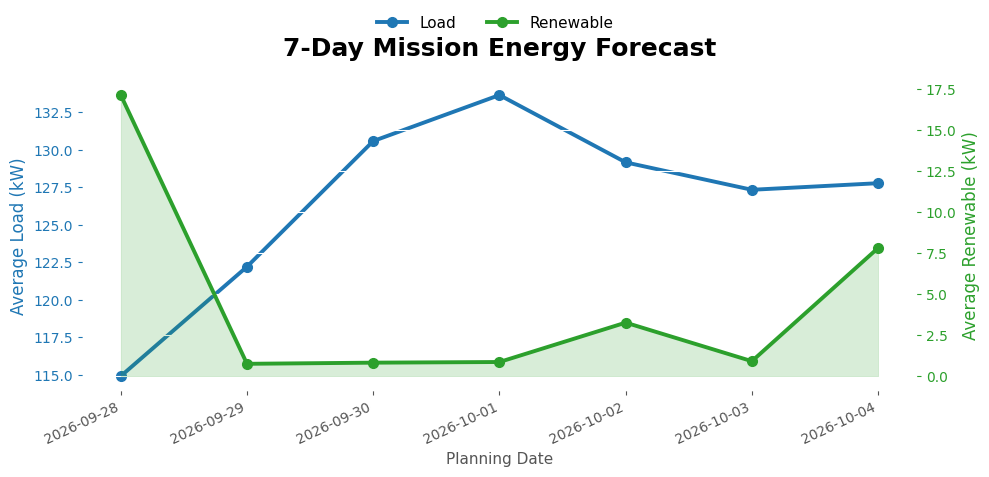

In [154]:
# ==========================================================
# 7.8.1 Daily Load vs Renewable Forecast
# ==========================================================

import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(10,5), facecolor="white")
ax1.set_facecolor("white")

# ----------------------------------------------------------
# Average Electrical Load
# ----------------------------------------------------------
ax1.plot(
    mission_dashboard["Date"],
    mission_dashboard["Average Load (kW)"],
    marker="o",
    linewidth=2.8,
    markersize=7,
    color="#1F77B4",
    label="Load"
)

ax1.set_ylabel(
    "Average Load (kW)",
    fontsize=12,
    color="#1F77B4"
)
ax1.tick_params(axis="y", colors="#1F77B4")
ax1.grid(True, linestyle="--", alpha=0.3)

# ----------------------------------------------------------
# Average Renewable Generation
# ----------------------------------------------------------
ax2 = ax1.twinx()

ax2.plot(
    mission_dashboard["Date"],
    mission_dashboard["Average Renewable (kW)"],
    marker="o",
    linewidth=2.8,
    markersize=7,
    color="#2CA02C",
    label="Renewable"
)

ax2.fill_between(
    mission_dashboard["Date"],
    mission_dashboard["Average Renewable (kW)"],
    color="#2CA02C",
    alpha=0.18
)

ax2.set_ylabel(
    "Average Renewable (kW)",
    fontsize=12,
    color="#2CA02C"
)
ax2.tick_params(axis="y", colors="#2CA02C")

# ----------------------------------------------------------
# Formatting
# ----------------------------------------------------------
plt.title(
    "7-Day Mission Energy Forecast",
    fontsize=18,
    weight="bold",
    pad=18
)

ax1.set_xlabel("Planning Date", fontsize=11)

plt.setp(ax1.get_xticklabels(), rotation=25, ha="right")

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

fig.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.96),
    ncol=2,
    frameon=False,
    fontsize=11
)

# Remove top borders
ax1.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)

plt.tight_layout(rect=[0,0,1,0.92])
plt.show()

## 7.9 AI Mission Decision Summary

The AI Energy Management System converts the 7-day forecast into an operational briefing. Each day is assigned a mission priority based on predicted operational risk, enabling proactive planning for power generation, fuel conservation, and station safety.

In [155]:
# ==========================================================
# 7.9 AI Mission Decision Summary
# ==========================================================

def mission_priority(risk):
    if risk == "High":
        return "Immediate Attention"
    elif risk == "Moderate":
        return "Monitor Conditions"
    else:
        return "Routine Operations"


mission_summary = mission_dashboard.copy()

mission_summary["Mission Priority"] = (
    mission_summary["Risk Level"]
    .apply(mission_priority)
)

# Professional recommendation wording
mission_summary["Daily Recommendation"] = (
    mission_summary["Daily Recommendation"]
    .replace({
        "Reduce non-critical loads":
            "Curtail non-critical loads",
        "Reserve battery for heating":
            "Reserve battery for critical heating",
        "Prioritize wind generation":
            "Prioritize wind generation",
        "Secure operations + maximize wind":
            "Secure outdoor operations & maximize wind"
    })
)

# Final commander dashboard
mission_summary = mission_summary[[
    "Date",
    "Risk Level",
    "Mission Priority",
    "Daily Recommendation",
    "Average Load (kW)",
    "Average Renewable (kW)",
    "Average Generator Loading (%)",
    "Average Temperature (°C)",
    "Average Wind Speed (m/s)"
]]

mission_summary

,Date,Risk Level,Mission Priority,Daily Recommendation,Average Load (kW),Average Renewable (kW),Average Generator Loading (%),Average Temperature (°C),Average Wind Speed (m/s)
0,2026-09-28,Moderate,Monitor Conditions,Prioritize wind generation,114.91,17.13,65.2,-11.9,15.51
1,2026-09-29,Moderate,Monitor Conditions,Operate in optimal generator zone,122.21,0.75,81.0,-16.9,2.31
2,2026-09-30,High,Immediate Attention,Curtail non-critical loads,130.59,0.82,86.5,-22.8,2.64
3,2026-10-01,High,Immediate Attention,Curtail non-critical loads,133.66,0.86,88.5,-21.6,2.11
4,2026-10-02,High,Immediate Attention,Curtail non-critical loads,129.17,3.26,83.9,-17.5,7.34
5,2026-10-03,High,Immediate Attention,Curtail non-critical loads,127.34,0.91,84.3,-15.7,3.10
6,2026-10-04,Moderate,Monitor Conditions,Operate in optimal generator zone,127.78,7.81,80.0,-16.6,7.97


## 7.10 Historical Operational Dashboard

Before exporting, the full historical Bharati record is aggregated into a daily analytics table (load, renewable output, weather, and AI-flagged anomalies). This feeds the historical-analytics page of the operator dashboard, separate from the 7-day forward-looking plan above.


In [156]:
# ==========================================================
# 7.10 Historical Operational Dashboard
# ==========================================================

historical_dashboard = (
    train_df
    .assign(Date=train_df["timestamp"].dt.date)
    .groupby("Date")
    .agg({
        "total_load_kw": "mean",
        "renewable_kw": "mean",
        "renewable_ratio": "mean",
        "temp_c": "mean",
        "wind_speed_ms": "mean",
        "system_status": lambda x: (x == "Anomaly").sum()
    })
    .reset_index()
)

historical_dashboard.columns = [
    "Date",
    "Average Load (kW)",
    "Average Renewable (kW)",
    "Renewable Contribution (%)",
    "Average Temperature (°C)",
    "Average Wind Speed (m/s)",
    "Anomaly Count"
]

historical_dashboard["Renewable Contribution (%)"] = (
    historical_dashboard["Renewable Contribution (%)"] * 100
)

historical_dashboard = historical_dashboard.round({
    "Average Load (kW)": 2,
    "Average Renewable (kW)": 2,
    "Renewable Contribution (%)": 2,
    "Average Temperature (°C)": 1,
    "Average Wind Speed (m/s)": 2
})

historical_dashboard.head()

,Date,Average Load (kW),Average Renewable (kW),Renewable Contribution (%),Average Temperature (°C),Average Wind Speed (m/s),Anomaly Count
0,2002-01-01,117.02,25.35,21.77,1.8,9.50,1
1,2002-01-02,119.48,13.32,11.16,0.1,4.03,0
2,2002-01-03,120.03,13.37,11.20,-0.2,5.28,0
3,2002-01-04,121.37,13.99,11.52,-1.2,5.69,0
4,2002-01-05,118.19,13.24,11.22,1.1,4.94,0


# Section 8 — Dashboard Export Layer

The final processed datasets are exported as CSV files for visualization in Power BI.

Each exported dataset serves a dedicated dashboard page, ensuring separation between historical analytics, optimization results, and future operational planning.

In [157]:
# ==========================================================
# 8.1 Export Final Dashboard Datasets
# ==========================================================

executive_summary.to_csv(
    "executive_summary.csv",
    index=False
)

historical_dashboard.to_csv(
    "historical_dashboard.csv",
    index=False
)

monthly_dashboard.to_csv(
    "monthly_fuel.csv",
    index=False
)

feature_importance.to_csv(
    "feature_importance.csv",
    index=False
)

mission_dashboard.to_csv(
    "weekly_operational_plan.csv",
    index=False
)

mission_summary.to_csv(
    "mission_decision_summary.csv",
    index=False
)

ai_alerts.to_csv(
    "alerts.csv",
    index=False
)

print("All Polaris dashboard datasets exported successfully.")

All Polaris dashboard datasets exported successfully.


In [158]:
# ==========================================================
# 8.2 Verify Exported Files
# ==========================================================

import os
import pandas as pd

export_files = [
    "executive_summary.csv",
    "historical_dashboard.csv",
    "monthly_fuel.csv",
    "feature_importance.csv",
    "weekly_operational_plan.csv",
    "mission_decision_summary.csv"
]

verification = pd.DataFrame({
    "Dataset": export_files,
    "Exported": [os.path.exists(f) for f in export_files]
})

verification

,Dataset,Exported
0,executive_summary.csv,True
1,historical_dashboard.csv,True
2,monthly_fuel.csv,True
3,feature_importance.csv,True
4,weekly_operational_plan.csv,True
5,mission_decision_summary.csv,True
